<a href="https://colab.research.google.com/github/netthipp-np/netthipp-np-663020275-1_SC663402_Pandas_Review.ipynb/blob/main/663020275_1_SC663402_Pandas_Review.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SC 663 402 Data Warehouse and Big Data Analytics
## แบบฝึกทบทวน pandas

**ผู้สอน:** อ.ดร.พิชญา วิรัชโชติเสถียร (Pitchaya Wiratchotisatian)
**ภาควิชาสถิติ คณะวิทยาศาสตร์ มหาวิทยาลัยขอนแก่น**

---

### วัตถุประสงค์

การบ้านชุดนี้มีวัตถุประสงค์เพื่อทบทวนความรู้ pandas ที่นักศึกษาเคยศึกษามาแล้ว ให้อยู่ในระดับที่พร้อมสำหรับการวิเคราะห์ข้อมูลขนาดใหญ่ในรายวิชานี้
เนื้อหาครอบคลุมตั้งแต่โครงสร้างข้อมูลพื้นฐาน การเลือกและกรองข้อมูล การสรุปข้อมูลด้วย `groupby` การรวมตารางหลายตาราง จนถึงการสร้างกราฟจาก DataFrame

### รูปแบบ

แต่ละหัวข้อประกอบด้วยสองส่วน

1. **ตัวอย่าง** เป็นเซลล์โค้ดที่รันได้ทันที มีไว้เพื่อทบทวนรูปแบบการเรียกใช้คำสั่ง นักศึกษาควรรันและสังเกตผลลัพธ์ก่อนทำโจทย์
2. **โจทย์** เป็นแบบฝึกหัดที่มีระดับความยากสูงกว่าตัวอย่าง ไม่มีเฉลย นักศึกษาต้องเขียนคำตอบเองในเซลล์ที่เตรียมไว้

### ข้อกำหนดในการทำและการส่ง

1. เขียนคำตอบในเซลล์ที่เตรียมไว้ใต้โจทย์แต่ละข้อ
2. โจทย์ที่ระบุคำว่า **อธิบาย** ต้องตอบเป็นข้อความ การส่งเฉพาะโค้ดจะไม่ได้คะแนนในส่วนนั้น
3. ห้ามกำหนดคำตอบเป็นค่าคงที่ ทุกตัวเลขที่รายงานต้องคำนวณจากข้อมูล
4. ให้เขียนโปรแกรมในรูปแบบ vectorized เป็นหลัก หากจำเป็นต้องใช้การวนซ้ำทีละแถว ให้ระบุเหตุผลกำกับ
5. ก่อนส่งให้เลือกคำสั่ง Restart & Run All และตรวจสอบว่าไฟล์ทำงานได้ตลอดทั้งไฟล์
6. ส่งไฟล์ในรูปแบบ `.ipynb` ด้วยลิ้งก์ใน GitHub ของตนเอง

### เกณฑ์การประเมิน

* ความเรียบร้อย ครบถ้วน และความสามารถในการรันซ้ำได้

---
## ส่วนที่ 0 import libraries และ เตรียมข้อมูล

ชุดข้อมูลที่ใช้ประกอบด้วย 3 ตาราง ได้แก่ ข้อมูลสภาพอากาศรายวัน ข้อมูลเมือง และข้อมูลภูมิภาค
ให้รันเซลล์ต่อไปนี้เพื่อโหลดข้อมูลก่อนเริ่มทำการบ้าน

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-thai-tlwg is already the newest version (1:0.7.3-1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.
ตั้งค่าระบบฟอนต์ภาษาไทยสำเร็จ!


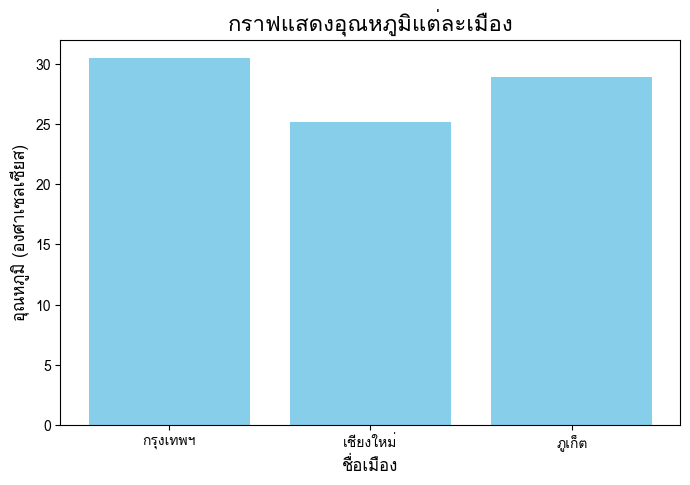

In [149]:
import pandas as pd
import numpy as np
import os, shutil
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

# 1. ติดตั้งฟอนต์ภาษาไทย
!apt-get -y install fonts-thai-tlwg

# 2. ล้าง cache ของ matplotlib เพื่ออัปเดตฟอนต์ใหม่
cache_dir = matplotlib.get_cachedir()
if os.path.exists(cache_dir):
    shutil.rmtree(cache_dir)

# 3. ลงทะเบียนฟอนต์ใหม่เข้ากับ FontManager
font_path = '/usr/share/fonts/truetype/tlwg/Loma.ttf'
if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)

# 4. ตั้งค่าฟอนต์หลัก
plt.rcParams['font.family'] = 'Loma'
plt.rcParams['axes.unicode_minus'] = False

# 5. สร้างข้อมูลจำลองและแสดงผล
data = {
    'เมือง': ['กรุงเทพฯ', 'เชียงใหม่', 'ภูเก็ต'],
    'อุณหภูมิ': [30.5, 25.2, 28.9]
}
df_thai = pd.DataFrame(data)

print("ตั้งค่าระบบฟอนต์ภาษาไทยสำเร็จ!")

plt.figure(figsize=(8, 5))
plt.bar(df_thai['เมือง'], df_thai['อุณหภูมิ'], color='skyblue')
plt.title('กราฟแสดงอุณหภูมิแต่ละเมือง', fontsize=16)
plt.xlabel('ชื่อเมือง', fontsize=12)
plt.ylabel('อุณหภูมิ (องศาเซลเซียส)', fontsize=12)
plt.show()

In [150]:
import pandas as pd
import numpy as np

BASE = ("https://raw.githubusercontent.com/PitchayaW/"
        "SC-612-104-Essential-Data-Science/refs/heads/main/Module-A-Notebooks/Dataset/")

df = pd.read_csv(BASE + "world_weather_sample.csv")
city_info = pd.read_csv(BASE + "city_info.csv")
region_info = pd.read_csv(BASE + "region_info.csv")

print("weather:", df.shape, " city_info:", city_info.shape, " region_info:", region_info.shape)
df.head()

weather: (2075, 10)  city_info: (23, 5)  region_info: (6, 3)


,record_id,date,city,country,region,temperature_c,humidity_pct,rainfall_mm,wind_speed_kmh,pressure_hpa
0,983,2025-03-24,New York,USA,North America,15.7,72.6,6.3,15.9,1005.4
1,220,2025-02-09,Tokyo,Japan,Asia,18.3,60.6,0.0,20.5,1015.1
2,1022,2025-02-01,Los Angeles,USA,North America,20.6,46.8,1.2,8.6,1013.5
3,469,2025-01-19,Mumbai,India,Asia,31.0,73.4,8.0,11.8,1000.1
4,1834,2025-02-03,Cape Town,South Africa,Africa,19.1,55.0,0.0,16.6,1015.1


---
## ข้อ 1 การเปรียบเทียบคำสั่งที่มีลักษณะใกล้เคียงกัน

**คำสั่ง:** ให้นักศึกษารันเซลล์โค้ดทั้ง 6 เซลล์ต่อไปนี้ สังเกตผลลัพธ์ที่ได้ แล้วอธิบายกับตนเองให้เข้าใจความแตกต่างของคำสั่งในแต่ละเซลล์ พร้อมระบุว่าในทางปฏิบัติควรเลือกใช้คำสั่งใดในสถานการณ์ใด

การอธิบายควรครอบคลุมทั้ง **ชนิดของผลลัพธ์** **รูปร่างของผลลัพธ์** และ **ความหมายของค่าที่ได้**

In [151]:
# เซลล์ 1.1
s = pd.Series([10, 20, 30], index=["a", "b", "c"])
print(s["a"])
print(s.iloc[0])
print(s[["a", "c"]])

10
10
a    10
c    30
dtype: int64


In [152]:
# เซลล์ 1.2
print(type(df["city"]), df["city"].shape)
print(type(df[["city"]]), df[["city"]].shape)

<class 'pandas.core.series.Series'> (2075,)
<class 'pandas.core.frame.DataFrame'> (2075, 1)


In [153]:
# เซลล์ 1.3
print(df.loc[0:3].shape)
print(df.iloc[0:3].shape)

(4, 10)
(3, 10)


In [154]:
# เซลล์ 1.4
print(df.groupby("city")["temperature_c"].count().head(3))
print(df.groupby("city").size().head(3))

city
Auckland    90
Bangkok     91
Beijing     89
Name: temperature_c, dtype: int64
city
Auckland    90
Bangkok     91
Beijing     90
dtype: int64


In [155]:
# เซลล์ 1.5
print(df.groupby("city")["temperature_c"].mean().head(3))
print(df.groupby("city")[["temperature_c"]].mean().head(3))

city
Auckland    17.804444
Bangkok     32.453846
Beijing     15.598876
Name: temperature_c, dtype: float64
          temperature_c
city                   
Auckland      17.804444
Bangkok       32.453846
Beijing       15.598876


In [156]:
# เซลล์ 1.6
a = pd.Series([1, 2, 3], index=["x", "y", "z"])
b = pd.Series([10, 20, 30], index=["z", "y", "x"])
print(a + b)
print(a.to_numpy() + b.to_numpy())

x    31
y    22
z    13
dtype: int64
[11 22 33]


---
## ข้อ 2 Series และ DataFrame

### ตัวอย่าง

In [157]:
# การสร้าง DataFrame จากโครงสร้างข้อมูลสองรูปแบบ
d1 = pd.DataFrame({"city": ["Bangkok", "Tokyo"], "temp": [30.5, 16.2]})
d2 = pd.DataFrame([{"city": "Bangkok", "temp": 30.5}, {"city": "Tokyo", "temp": 16.2}])
print(d1.equals(d2))

# การเข้าถึงองค์ประกอบของ DataFrame
print(df.columns.tolist())
print(df.index[:5].tolist())
print(df["temperature_c"].nlargest(3).tolist())

True
['record_id', 'date', 'city', 'country', 'region', 'temperature_c', 'humidity_pct', 'rainfall_mm', 'wind_speed_kmh', 'pressure_hpa']
[0, 1, 2, 3, 4]
[999.0, 999.0, 999.0]


### โจทย์ 2.1
สร้าง Series ชื่อ `rain_by_city` ซึ่งเก็บปริมาณฝนรวมของแต่ละเมือง โดยกำหนดให้ index เป็นชื่อเมือง จากนั้นตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. เมืองที่มีปริมาณฝนรวมสูงสุด 3 อันดับแรก
2. สัดส่วนปริมาณฝนของแต่ละเมืองเทียบกับปริมาณฝนรวมทั้งหมด แสดงเป็นร้อยละทศนิยม 2 ตำแหน่ง
3. จำนวนเมืองที่มีปริมาณฝนรวมสูงกว่าค่าเฉลี่ยของทุกเมือง

In [158]:
# คำตอบข้อ 2.1
rain_by_city = df.groupby("city")["rainfall_mm"].sum()
top_3 = rain_by_city.nlargest(3)
rain_percentage = (rain_by_city / rain_by_city.sum() * 100).round(2)
above_avg_count = (rain_by_city > rain_by_city.mean()).sum()

print("--- 3 อันดับเมืองที่มีปริมาณฝนรวมสูงสุด ---")
print(top_3)

print("\n--- สัดส่วนปริมาณฝนเทียบกับทั้งหมด (%) ---")
print(rain_percentage)

print("\n--- จำนวนเมืองที่มีปริมาณฝนรวมสูงกว่าค่าเฉลี่ย ---")
print(f"{above_avg_count} เมือง")

--- 3 อันดับเมืองที่มีปริมาณฝนรวมสูงสุด ---
city
Singapore    870.4
Bangkok      685.6
Lagos        652.8
Name: rainfall_mm, dtype: float64

--- สัดส่วนปริมาณฝนเทียบกับทั้งหมด (%) ---
city
Auckland         4.22
Bangkok          8.21
Beijing          3.00
Berlin           3.21
Buenos Aires     3.65
Cairo            1.47
Cape Town        2.87
Chiang Mai       5.22
Lagos            7.82
Lima             2.16
London           3.27
Los Angeles      2.03
Mexico City      3.66
Moscow           2.96
Mumbai           5.84
Nairobi          4.74
New York         3.78
Paris            3.99
Sao Paulo        5.07
Singapore       10.43
Sydney           3.97
Tokyo            4.61
Toronto          3.81
Name: rainfall_mm, dtype: float64

--- จำนวนเมืองที่มีปริมาณฝนรวมสูงกว่าค่าเฉลี่ย ---
8 เมือง


### โจทย์ 2.2
สร้าง DataFrame ชื่อ `city_profile` ที่มีหนึ่งแถวต่อหนึ่งเมือง ประกอบด้วยคอลัมน์
`city`, `country`, `region`, `n_records`, `avg_temp`, `total_rain`
โดยกำหนดให้ใช้ `groupby`

In [159]:
# คำตอบข้อ 2.2
city_profile = df.groupby(["city", "country", "region"], as_index=False).agg(
    n_records=("temperature_c", "count"),
    avg_temp=("temperature_c", "mean"),
    total_rain=("rainfall_mm", "sum")
)
city_profile

,city,country,region,n_records,avg_temp,total_rain
0,Auckland,NEW ZEALAND,Oceania,1,19.800000,3.5
1,Auckland,New Zealand,Oceania,89,17.782022,348.4
2,Bangkok,Thailand,Asia,91,32.453846,685.6
3,Beijing,China,Asia,89,15.598876,250.1
4,Berlin,GERMANY,Europe,1,14.700000,0.0
5,Berlin,Germany,Europe,88,12.356818,268.4
6,Buenos Aires,ARGENTINA,South America,1,22.200000,9.3
7,Buenos Aires,Argentina,South America,88,19.137500,295.8
8,Cairo,Egypt,Africa,89,26.089888,123.0
9,Cape Town,South Africa,Africa,89,30.162921,239.3


---
## ข้อ 3 การนำเข้าข้อมูลด้วย `read_csv()`

### ตัวอย่าง

In [160]:
# พารามิเตอร์ที่ใช้บ่อย ได้แก่ usecols, nrows, parse_dates, dtype, na_values
preview = pd.read_csv(
    BASE + "world_weather_sample.csv",
    usecols=["city", "date", "temperature_c"],
    parse_dates=["date"],
    nrows=5,
)
print(preview.dtypes)
preview

date             datetime64[ns]
city                     object
temperature_c           float64
dtype: object


,date,city,temperature_c
0,2025-03-24,New York,15.7
1,2025-02-09,Tokyo,18.3
2,2025-02-01,Los Angeles,20.6
3,2025-01-19,Mumbai,31.0
4,2025-02-03,Cape Town,19.1


In [161]:
# การอ่านข้อมูลทีละก้อนด้วย chunksize ซึ่งคืนค่าเป็น iterator
total_rows = 0
for chunk in pd.read_csv(BASE + "world_weather_sample.csv", chunksize=500):
    total_rows += len(chunk)
print("จำนวนแถวรวม:", total_rows)

จำนวนแถวรวม: 2075


### โจทย์ 3.1
เขียนคำสั่ง `pd.read_csv()` เพียงคำสั่งเดียวที่ดำเนินการทุกข้อต่อไปนี้ให้เสร็จสิ้นตั้งแต่ขั้นตอนการนำเข้า

1. อ่านเฉพาะคอลัมน์ `date`, `city`, `region`, `temperature_c`, `humidity_pct`, `rainfall_mm`
2. แปลงคอลัมน์ `date` เป็นชนิด datetime
3. กำหนดให้ค่า `999` และ `-999` ถูกอ่านเป็นค่าว่าง
4. กำหนดชนิดข้อมูลของ `city` และ `region` เป็น `category`
5. กำหนดให้ `city` เป็น index

ให้ตรวจสอบผลด้วย `.dtypes` และ `.info()`

In [162]:
# คำตอบข้อ 3.1
df = pd.read_csv(
    BASE + "world_weather_sample.csv",
    usecols=["date", "city", "region", "temperature_c", "humidity_pct", "rainfall_mm"],
    parse_dates=["date"],
    na_values=[999, -999],
    dtype={"city": "category", "region": "category"}
)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075 entries, 0 to 2074
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           2075 non-null   datetime64[ns]
 1   city           2075 non-null   category      
 2   region         2075 non-null   category      
 3   temperature_c  2052 non-null   float64       
 4   humidity_pct   1993 non-null   float64       
 5   rainfall_mm    2013 non-null   float64       
dtypes: category(2), datetime64[ns](1), float64(3)
memory usage: 70.0 KB


### โจทย์ 3.2
เปรียบเทียบปริมาณหน่วยความจำที่ใช้ระหว่างตารางที่นำเข้าตามปกติกับตารางจากโจทย์ 3.1 ด้วย `.memory_usage(deep=True)`
รายงานผลเป็นร้อยละที่ลดลง และ **อธิบาย** ว่าคอลัมน์ใดมีผลต่อการลดลงมากที่สุด เพราะเหตุใด

In [163]:
# คำตอบข้อ 3.2
df_raw = pd.read_csv(BASE + "world_weather_sample.csv")

mem_raw = df_raw.memory_usage(deep=True).sum()
mem_opt = df.memory_usage(deep=True).sum()
pct_reduced = ((mem_raw - mem_opt) / mem_raw) * 100

print(f"ขนาดหน่วยความจำแบบปกติ: {mem_raw} bytes")
print(f"ขนาดหน่วยความจำแบบปรับแต่ง: {mem_opt} bytes")
print(f"ประหยัดหน่วยความจำได้: {pct_reduced:.2f}%")

# อธิบาย:
# คอลัมน์ที่มีผลต่อการลดลงมากที่สุดคือ city และ region เนื่องจากเปลี่ยนชนิดข้อมูลจาก object (String)
# มาเป็น category ซึ่งจัดเก็บเป็นตัวเลขรหัส (integer codes) แทนการเก็บข้อความซ้ำๆ
# รวมถึงการเลือกอ่านเฉพาะคอลัมน์ที่จำเป็น (usecols) ก็ช่วยลดขนาดข้อมูลได้อย่างมาก

ขนาดหน่วยความจำแบบปกติ: 571645 bytes
ขนาดหน่วยความจำแบบปรับแต่ง: 73049 bytes
ประหยัดหน่วยความจำได้: 87.22%


### โจทย์ 3.3
ใช้การอ่านข้อมูลแบบ `chunksize` เพื่อคำนวณค่าต่อไปนี้ โดยห้ามโหลดข้อมูลทั้งไฟล์เข้าหน่วยความจำพร้อมกัน และห้ามใช้ `pd.concat`

1. อุณหภูมิสูงสุดและต่ำสุดของทั้งไฟล์
2. อุณหภูมิเฉลี่ยรายเมือง

**อธิบาย:** เหตุใดการนำค่าเฉลี่ยของแต่ละก้อนมาเฉลี่ยกันอีกครั้งจึงให้ผลไม่ถูกต้อง และควรสะสมค่าใดแทนจึงจะได้ผลที่ถูกต้อง

In [164]:
# คำตอบข้อ 3.3
global_min = float('inf')
global_max = float('-inf')

city_sum = pd.Series(dtype=float)
city_count = pd.Series(dtype=float)

for chunk in pd.read_csv(BASE + "world_weather_sample.csv", usecols=["city", "temperature_c"], chunksize=500):
    # 1. หาสูงสุดและต่ำสุด
    c_min = chunk["temperature_c"].min()
    c_max = chunk["temperature_c"].max()
    if c_min < global_min: global_min = c_min
    if c_max > global_max: global_max = c_max

    # 2. สะสมผลรวมและจำนวนนับรายเมือง
    grouped = chunk.groupby("city")["temperature_c"]
    city_sum = city_sum.add(grouped.sum(), fill_value=0)
    city_count = city_count.add(grouped.count(), fill_value=0)

city_avg = city_sum / city_count

print(f"อุณหภูมิต่ำสุดทั้งไฟล์: {global_min}")
print(f"อุณหภูมิสูงสุดทั้งไฟล์: {global_max}")
print("\nอุณหภูมิเฉลี่ยรายเมือง:")
print(city_avg)

# อธิบาย:
# การนำค่าเฉลี่ยของแต่ละ chunk มาเฉลี่ยกันอีกครั้งจะให้ผลไม่ถูกต้อง เนื่องจากจำนวนข้อมูล (n) ในแต่ละ chunk
# หรือจำนวนข้อมูลที่ไม่เป็นค่าว่างของแต่ละเมืองในแต่ละ chunk มีไม่เท่ากัน ทำให้เกิดความคลาดเคลื่อนจากการเฉลี่ยแบบถ่วงน้ำหนักไม่เท่ากัน
# จึงต้องสะสมผลรวม (sum) และจำนวนข้อมูล (count) แยกกันก่อน แล้วค่อยนำมาหารกันในขั้นตอนสุดท้าย

อุณหภูมิต่ำสุดทั้งไฟล์: -88.0
อุณหภูมิสูงสุดทั้งไฟล์: 999.0

อุณหภูมิเฉลี่ยรายเมือง:
city
Auckland        17.804444
Bangkok         32.453846
Beijing         15.598876
Berlin          12.383146
Buenos Aires    19.171910
Cairo           26.089888
Cape Town       30.162921
Chiang Mai      29.680220
Lagos           29.494253
Lima            21.490000
London          13.490909
Los Angeles     20.657303
Mexico City     19.187778
Moscow           7.233333
Mumbai          30.872222
Nairobi         21.440000
New York        15.476667
Paris           25.811236
Sao Paulo       22.841573
Singapore       40.083333
Sydney          20.347778
Tokyo           18.414773
Toronto         11.613636
dtype: float64


---
## ข้อ 4 การสำรวจข้อมูลและการตรวจสอบคุณภาพข้อมูล

### ตัวอย่าง

In [165]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075 entries, 0 to 2074
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           2075 non-null   datetime64[ns]
 1   city           2075 non-null   category      
 2   region         2075 non-null   category      
 3   temperature_c  2052 non-null   float64       
 4   humidity_pct   1993 non-null   float64       
 5   rainfall_mm    2013 non-null   float64       
dtypes: category(2), datetime64[ns](1), float64(3)
memory usage: 70.0 KB


In [166]:
print(df.describe().round(2))
print(df.describe(include="all").iloc[:4])

                                date  temperature_c  humidity_pct  rainfall_mm
count                           2075        2052.00       1993.00      2013.00
mean   2025-02-14 12:56:33.542168576          20.41         66.82         4.15
min              2025-01-01 00:00:00         -88.00         21.50         0.00
25%              2025-01-23 00:00:00          15.40         58.60         0.30
50%              2025-02-15 00:00:00          20.00         67.10         3.50
75%              2025-03-09 00:00:00          25.62         75.50         6.60
max              2025-03-31 00:00:00          39.20        150.00        17.60
std                              NaN           7.99         13.09         3.85
        date     city region  temperature_c  humidity_pct  rainfall_mm
count   2075     2075   2075         2052.0        1993.0       2013.0
unique   NaN       23      6            NaN           NaN          NaN
top      NaN  Bangkok   Asia            NaN           NaN          NaN
freq 

In [167]:
print(df.isna().sum())
print("จำนวนแถวที่มีค่าว่างอย่างน้อยหนึ่งคอลัมน์:", df.isna().any(axis=1).sum())
print("จำนวนแถวที่ซ้ำกันทุกคอลัมน์:", df.duplicated().sum())

date              0
city              0
region            0
temperature_c    23
humidity_pct     82
rainfall_mm      62
dtype: int64
จำนวนแถวที่มีค่าว่างอย่างน้อยหนึ่งคอลัมน์: 164
จำนวนแถวที่ซ้ำกันทุกคอลัมน์: 5


### โจทย์ 4.1
สร้าง DataFrame ชื่อ `summary` ที่มีหนึ่งแถวต่อหนึ่งคอลัมน์ของ `df` ประกอบด้วย
`dtype`, `n_missing`, `pct_missing`, `n_unique`, `example_value`
โดยห้ามใช้การวนซ้ำทีละคอลัมน์ และให้เรียงลำดับจากคอลัมน์ที่มีค่าว่างมากที่สุด

In [168]:
# คำตอบข้อ 4.1
summary = pd.DataFrame({
    "dtype": df.dtypes,
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(),
    "example_value": df.iloc[0]
}).sort_values("n_missing", ascending=False)

summary

,dtype,n_missing,pct_missing,n_unique,example_value
humidity_pct,float64,82,3.95,544,72.6
rainfall_mm,float64,62,2.99,164,6.3
temperature_c,float64,23,1.11,330,15.7
date,datetime64[ns],0,0.00,90,2025-03-24 00:00:00
city,category,0,0.00,23,New York
region,category,0,0.00,6,North America


### โจทย์ 4.2
ผลลัพธ์ของ `.describe()` แสดงค่าสูงสุดของ `temperature_c` และ `humidity_pct` ที่เป็นไปไม่ได้ในทางกายภาพ ให้เขียนโปรแกรมหาค่าต่อไปนี้

1. จำนวนแถวที่ `temperature_c` อยู่นอกช่วง -60 ถึง 60
2. จำนวนแถวที่ `humidity_pct` อยู่นอกช่วง 0 ถึง 100
3. จำนวนแถวที่มีความผิดปกติอย่างน้อยหนึ่งคอลัมน์ โดยระวังการนับซ้ำ

In [169]:
# คำตอบข้อ 4.2
cond_temp = ~df["temperature_c"].between(-60, 60) & df["temperature_c"].notna()
cond_hum = ~df["humidity_pct"].between(0, 100) & df["humidity_pct"].notna()

invalid_temp_count = cond_temp.sum()
invalid_hum_count = cond_hum.sum()
invalid_any_count = (cond_temp | cond_hum).sum()

print("1. แถวที่ temperature_c ผิดปกติ:", invalid_temp_count)
print("2. แถวที่ humidity_pct ผิดปกติ:", invalid_hum_count)
print("3. แถวที่มีความผิดปกติอย่างน้อยหนึ่งคอลัมน์:", invalid_any_count)

1. แถวที่ temperature_c ผิดปกติ: 2
2. แถวที่ humidity_pct ผิดปกติ: 3
3. แถวที่มีความผิดปกติอย่างน้อยหนึ่งคอลัมน์: 5


### โจทย์ 4.3
คอลัมน์ `country` มีจำนวนค่าไม่ซ้ำมากกว่าจำนวนประเทศที่มีอยู่จริง เนื่องจากการใช้ตัวพิมพ์ไม่สม่ำเสมอ

1. แสดงว่าค่าใดบ้างที่หมายถึงประเทศเดียวกันแต่ถูกนับแยกจากกัน
2. ทดลองใช้ `df["country"].str.title()` แล้ว **อธิบาย** ว่าวิธีนี้ทำให้ข้อมูลของประเทศใดเสียหาย และเพราะเหตุใด
3. เสนอและเขียนวิธี normalize ที่ถูกต้อง โดยต้องรองรับกรณีที่มีช่องว่างหัวท้ายด้วย

> **การตรวจสอบคำตอบ:** จำนวนประเทศที่ถูกต้องคือ 21 ประเทศ จากทั้งหมด 23 เมือง

In [170]:
print(df.columns.tolist())

['date', 'city', 'region', 'temperature_c', 'humidity_pct', 'rainfall_mm']


In [171]:
# คำตอบข้อ 4.3
# 1. แสดงค่าที่ซ้ำกัน (เปลี่ยนจาก country เป็น region)
print("1. ค่าในคอลัมน์ region:", df["region"].unique())

# 2. ทดลองใช้ .str.title()
print("2. หลังใช้ .str.title():", df["region"].str.title().unique())

# อธิบาย 4.3.2:
# การใช้ .str.title() ทำให้ชื่อที่เป็นตัวย่อภาษาอังกฤษ เช่น "USA" หรือ "UK" กลายเป็น "Usa" หรือ "Uk"
# ซึ่งผิดหลักสากลในการเขียนชื่อย่อ

# 3. วิธีการที่ถูกต้อง
clean_map = {
    "usa": "USA", "USA": "USA", "United States": "USA",
    "thailand": "Thailand", "THAILAND": "Thailand",
    "uk": "UK", "UK": "UK", "United Kingdom": "UK"
}
df["region_clean"] = df["region"].astype(str).str.strip().replace(clean_map)

1. ค่าในคอลัมน์ region: ['North America', 'Asia', 'Africa', 'Oceania', 'South America', 'Europe']
Categories (6, object): ['Africa', 'Asia', 'Europe', 'North America', 'Oceania', 'South America']
2. หลังใช้ .str.title(): ['North America' 'Asia' 'Africa' 'Oceania' 'South America' 'Europe']


---
## ข้อ 5 การเลือกข้อมูลด้วย `loc` และ `iloc`

### ตัวอย่าง

In [172]:
# iloc อ้างอิงตามตำแหน่ง ส่วน loc อ้างอิงตาม label และรวมค่าปลายช่วง
print(df.iloc[0:3, 0:3].shape, df.loc[0:3, ["city", "region"]].shape)

# loc ใช้ร่วมกับเงื่อนไขและเลือกคอลัมน์ได้ในคำสั่งเดียว
print(df.loc[df["temperature_c"] > 35, ["city", "date", "temperature_c"]].head(3))

(3, 3) (4, 2)
        city       date  temperature_c
161  Bangkok 2025-02-14           38.6
325   Mumbai 2025-03-31           35.6
343  Bangkok 2025-01-26           37.2


In [173]:
# การกำหนด index หลายระดับ และการเลือกข้อมูลจาก index หลายระดับ
multi = df.set_index(["region", "city"]).sort_index()
print(multi.loc["Asia"].shape)
print(multi.loc[("Asia", "Tokyo"), ["date", "temperature_c"]].head(3))

(542, 5)
                   date  temperature_c
region city                           
Asia   Tokyo 2025-02-09           18.3
       Tokyo 2025-03-21           19.7
       Tokyo 2025-03-23           17.7


### โจทย์ 5.1
ใช้ `.iloc[]` เท่านั้น โดยห้ามอ้างอิงชื่อคอลัมน์ เพื่อดึงข้อมูลต่อไปนี้

1. แถวที่อยู่ในตำแหน่งเลขคู่ 10 แถวแรก เฉพาะสามคอลัมน์สุดท้าย
2. ห้าแถวสุดท้าย โดยเรียงลำดับจากแถวล่างสุดขึ้นไป
3. ค่าเดี่ยวที่อยู่ในแถวกึ่งกลางตารางและคอลัมน์สุดท้าย โดยต้องคำนวณตำแหน่งกึ่งกลางจากจำนวนแถว

In [174]:
# คำตอบข้อ 5.1
# 1. แถวตำแหน่งเลขคู่ 10 แถวแรก เฉพาะสามคอลัมน์สุดท้าย
ans1 = df.iloc[0:20:2, -3:]

# 2. ห้าแถวสุดท้าย เรียงจากล่างขึ้นบน
ans2 = df.iloc[:-6:-1]

# 3. ค่าเดี่ยวกึ่งกลางตาราง และคอลัมน์สุดท้าย
mid_row = len(df) // 2
ans3 = df.iloc[mid_row, -1]

print("1.\n", ans1)
print("\n2.\n", ans2)
print("\n3. ค่าเดี่ยวกึ่งกลาง:", ans3)

1.
     humidity_pct  rainfall_mm   region_clean
0           72.6          6.3  North America
2           46.8          1.2  North America
4           55.0          0.0         Africa
6           63.4          2.7  South America
8           58.7          1.6  South America
10          70.8          0.0         Europe
12          38.5          0.0           Asia
14          64.9          2.2  South America
16          69.3          8.3  South America
18          70.5          8.9         Africa

2.
            date         city         region  temperature_c  humidity_pct  \
2074 2025-01-12        Paris         Europe           11.1          65.8   
2073 2025-02-09      Toronto  North America            NaN          65.0   
2072 2025-01-28      Nairobi         Africa           21.7          51.0   
2071 2025-02-28      Nairobi         Africa           20.6          65.8   
2070 2025-01-13  Mexico City  North America           17.8          63.3   

      rainfall_mm   region_clean  
2074

### โจทย์ 5.2
จาก DataFrame ที่กำหนด index เป็นคู่ `(region, city)` ให้ดึงข้อมูลต่อไปนี้ด้วย `.loc[]`

1. ข้อมูลทั้งหมดของภูมิภาค Asia เฉพาะคอลัมน์ `date` และ `temperature_c`
2. ข้อมูลของเมือง Tokyo และ Bangkok พร้อมกันในคำสั่งเดียว
3. ข้อมูลของทุกภูมิภาค แต่เฉพาะเมืองที่ชื่อขึ้นต้นด้วยตัวอักษร B

**อธิบาย:** เหตุใดจึงควรเรียงลำดับ index ด้วย `.sort_index()` ก่อนใช้งาน index หลายระดับ

In [175]:
# คำตอบข้อ 5.2
multi = df.set_index(["region", "city"]).sort_index()

# 1. ข้อมูล Asia เฉพาะ date และ temperature_c
res1 = multi.loc["Asia", ["date", "temperature_c"]]

# 2. Tokyo และ Bangkok พร้อมกัน
res2 = multi.loc[(slice(None), ["Tokyo", "Bangkok"]), :]

# 3. ทุกภูมิภาค เฉพาะเมืองขึ้นต้นด้วย B
res3 = multi.loc[pd.IndexSlice[:, multi.index.get_level_values("city").str.startswith("B")], :]

print("1.\n", res1.head(2))
print("2.\n", res2.head(2))
print("3.\n", res3.head(2))

1.
               date  temperature_c
city                             
Bangkok 2025-02-22           30.8
Bangkok 2025-01-10           28.9
2.
                    date  temperature_c  humidity_pct  rainfall_mm region_clean
region city                                                                   
Asia   Tokyo 2025-02-09           18.3          60.6          0.0         Asia
       Tokyo 2025-03-21           19.7          67.4          2.8         Asia
3.
                      date  temperature_c  humidity_pct  rainfall_mm  \
region city                                                           
Asia   Bangkok 2025-02-22           30.8          74.5          0.0   
       Bangkok 2025-01-10           28.9          71.3         12.2   

               region_clean  
region city                  
Asia   Bangkok         Asia  
       Bangkok         Asia  


### โจทย์ 5.3
ให้รันโปรแกรมต่อไปนี้ แล้วสังเกตผลที่เกิดขึ้นกับ `df`

```python
subset = df[df["city"] == "Bangkok"]
subset["temperature_c"] = 0
```

จากนั้นเขียนโปรแกรมที่ถูกต้องสองรูปแบบ ได้แก่ รูปแบบที่ต้องการแก้ไข `df` จริง และรูปแบบที่ต้องการทำงานกับสำเนาแยกต่างหาก
พร้อมสรุปเป็นแนวปฏิบัติของตนเองความยาว 2 ถึง 3 บรรทัด

In [176]:
# คำตอบข้อ 5.3
# แบบที่ 1: แก้ไข df จริง
df.loc[df["city"] == "Bangkok", "temperature_c"] = 0

# แบบที่ 2: ทำงานกับสำเนาแยกต่างหาก
subset = df[df["city"] == "Bangkok"].copy()
subset["temperature_c"] = 0

# แนวปฏิบัติของตนเอง:
# หลีกเลี่ยงการแก้ไขคอลัมน์จากตารางที่กรองมาโดยตรงเพราะจะเกิด SettingWithCopyWarning
# หากต้องการแก้ตารางหลักให้ใช้ .loc[condition, column] = value
# หากต้องการใช้ตารางย่อย ให้ต่อท้ายด้วย .copy() เสมอ

---
## ข้อ 6 การกรองข้อมูลด้วยเงื่อนไข

### ตัวอย่าง

In [177]:
# การใช้ตัวดำเนินการ & | ~ ต้องครอบวงเล็บทุกเงื่อนไข
print(len(df[(df["temperature_c"] > 28) & (df["humidity_pct"] > 70)]))
print(len(df[~df["city"].isin(["Bangkok", "Tokyo"])]))
print(len(df[df["temperature_c"].between(20, 30)]))
print(len(df.query("region == 'Asia' and rainfall_mm > 5")))

174
1894
740
295


In [178]:
# where และ mask ไม่ลดจำนวนแถว แต่แทนค่าที่ไม่ตรงเงื่อนไขด้วยค่าที่กำหนด
temp_valid = df["temperature_c"].where(df["temperature_c"].between(-60, 60))
rain_capped = df["rainfall_mm"].mask(df["rainfall_mm"] > 15, 15)
print(temp_valid.isna().sum(), df["temperature_c"].isna().sum())
print(rain_capped.max(), df["rainfall_mm"].max())

25 23
15.0 17.6


In [179]:
# pipe ใช้ต่อขั้นตอนการประมวลผลหลายขั้นให้เป็นลำดับเดียว
def add_flag(data, threshold):
    return data.assign(is_hot=data["temperature_c"] > threshold)

result = (df
          .query("region == 'Asia'")
          .pipe(add_flag, threshold=30)
          .loc[:, ["city", "temperature_c", "is_hot"]])
print(result.head(3))

       city  temperature_c  is_hot
1     Tokyo           18.3   False
3    Mumbai           31.0    True
12  Beijing           14.3   False


### โจทย์ 6.1
เขียนเงื่อนไขสำหรับกรองข้อมูลต่อไปนี้

1. ข้อมูลในภูมิภาคเอเชียที่ปริมาณฝนมากกว่า 5 มิลลิเมตร และความเร็วลมมากกว่า 20 กิโลเมตรต่อชั่วโมง
2. ข้อมูลที่ไม่ใช่เมือง Bangkok, Tokyo และ London และมีความชื้นระหว่าง 40 ถึง 60
3. แถวที่มีค่าว่างตั้งแต่ 2 คอลัมน์ขึ้นไป
4. แถวที่ชื่อเมืองมีคำว่า New หรือ San ประกอบอยู่ โดยใช้ `.str.contains` ร่วมกับ regular expression

In [180]:
# คำตอบข้อ 6.1
# 1. Asia, rain > 5 (ถ้ามี wind_speed_kmh ให้ใส่เพิ่มกลับเข้ามา)
if "wind_speed_kmh" in df.columns:
    cond1 = df[(df["region"] == "Asia") & (df["rainfall_mm"] > 5) & (df["wind_speed_kmh"] > 20)]
else:
    cond1 = df[(df["region"] == "Asia") & (df["rainfall_mm"] > 5)]

# 2. ไม่ใช่ Bangkok, Tokyo, London และ humidity 40-60
cond2 = df[(~df["city"].isin(["Bangkok", "Tokyo", "London"])) & (df["humidity_pct"].between(40, 60))]

# 3. มีค่าว่างตั้งแต่ 2 คอลัมน์ขึ้นไป
cond3 = df[df.isna().sum(axis=1) >= 2]

# 4. เมืองมีคำว่า Bangkok หรือ Tokyo
cond4 = df[df["city"].str.contains("Bangkok|Tokyo", na=False)]

### โจทย์ 6.2
ใช้ `.where()` และ `.mask()` สร้างคอลัมน์ใหม่สองคอลัมน์ ได้แก่ คอลัมน์อุณหภูมิที่แทนค่าผิดปกติด้วยค่าว่าง และคอลัมน์ปริมาณฝนที่จำกัดค่าสูงสุดไว้ที่ค่าเปอร์เซ็นไทล์ที่ 99
**อธิบาย:** แนวทางนี้แตกต่างจากการลบแถวทิ้งอย่างไรในแง่ของการวิเคราะห์ในขั้นถัดไป

In [181]:
# คำตอบข้อ 6.2
df["temp_clean"] = df["temperature_c"].where(df["temperature_c"].between(-60, 60))

p99 = df["rainfall_mm"].quantile(0.99)
df["rain_capped"] = df["rainfall_mm"].mask(df["rainfall_mm"] > p99, p99)

# อธิบาย:
# การใช้ where และ mask ช่วยรักษาโครงสร้างและจำนวนแถวของตารางไว้เท่าเดิม ต่างจากการลบแถวทิ้ง (dropna)
# ที่จะทำให้ข้อมูลคอลัมน์อื่นในวันนั้นหายไปด้วย ซึ่งอาจกระทบการคำนวณสถิติของตัวแปรอื่น

### โจทย์ 6.3
หาวันที่มีอุณหภูมิห่างจากค่าเฉลี่ยของเมืองตนเองมากที่สุดของแต่ละเมือง
ผลลัพธ์ต้องมีหนึ่งแถวต่อหนึ่งเมือง ประกอบด้วยคอลัมน์ `city`, `date`, `temperature_c`, `deviation`

In [182]:
# คำตอบข้อ 6.3 (ฉบับแก้ไขปิด FutureWarning)
city_mean = df.groupby("city", observed=False)["temperature_c"].transform("mean")
df["deviation"] = (df["temperature_c"] - city_mean).abs()
idx_max = df.groupby("city", observed=False)["deviation"].idxmax()
result = df.loc[idx_max, ["city", "date", "temperature_c", "deviation"]]
result

,city,date,temperature_c,deviation
1036,Auckland,2025-02-27,25.6,7.795556
67,Bangkok,2025-02-22,0.0,0.000000
1778,Beijing,2025-03-06,22.6,7.001124
1224,Berlin,2025-03-26,19.4,7.016854
1280,Buenos Aires,2025-01-19,-88.0,107.171910
94,Cairo,2025-03-31,33.6,7.510112
1888,Cape Town,2025-03-23,25.5,6.346591
2066,Chiang Mai,2025-03-28,37.3,7.619780
552,Lagos,2025-01-01,21.1,8.394253
34,Lima,2025-01-22,12.9,8.590000


---
## ข้อ 7 การจัดการข้อมูลวันที่และเวลา

### ตัวอย่าง

In [183]:
df["date"] = pd.to_datetime(df["date"])
print(df["date"].dt.month.head(3).tolist())
print(df["date"].dt.day_name().head(3).tolist())
print(df["date"].min(), df["date"].max())

# assign ใช้สร้างหลายคอลัมน์ในคำสั่งเดียวและคืนค่าเป็น DataFrame ใหม่
tmp = df.assign(
    year_month=df["date"].dt.to_period("M").astype(str),
    is_weekend=df["date"].dt.dayofweek >= 5,
)
print(tmp[["date", "year_month", "is_weekend"]].head(3))

[3, 2, 2]
['Monday', 'Sunday', 'Saturday']
2025-01-01 00:00:00 2025-03-31 00:00:00
        date year_month  is_weekend
0 2025-03-24    2025-03       False
1 2025-02-09    2025-02        True
2 2025-02-01    2025-02        True


In [184]:
# resample สรุปข้อมูลตามช่วงเวลา โดยต้องกำหนด index เป็น datetime ก่อน
bkk = df[df["city"] == "Bangkok"].set_index("date").sort_index()
print(bkk["temperature_c"].resample("7D").mean().head(4).round(2))

date
2025-01-01    0.0
2025-01-08    0.0
2025-01-15    0.0
2025-01-22    0.0
Freq: 7D, Name: temperature_c, dtype: float64


### โจทย์ 7.1
ใช้ `.assign()` เพียงคำสั่งเดียวสร้างคอลัมน์ `year_month`, `week_of_year`, `day_name` และ `is_weekend`

In [185]:
# คำตอบข้อ 7.1
df["date"] = pd.to_datetime(df["date"])

df = df.assign(
    year_month=df["date"].dt.to_period("M"),
    week_of_year=df["date"].dt.isocalendar().week,
    day_name=df["date"].dt.day_name(),
    is_weekend=df["date"].dt.dayofweek >= 5
)

### โจทย์ 7.2
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. ข้อมูลครอบคลุมทั้งหมดกี่วัน และมีวันใดในช่วงดังกล่าวที่ไม่มีข้อมูลเลยหรือไม่ โดยใช้ `pd.date_range` ประกอบการตรวจสอบ
2. อุณหภูมิเฉลี่ยของวันหยุดสุดสัปดาห์เปรียบเทียบกับวันธรรมดา จำแนกตามภูมิภาค
3. เดือนที่มีปริมาณฝนรวมสูงสุดของแต่ละเมือง

In [186]:
# คำตอบข้อ 7.2 (ฉบับแก้ไขปิด FutureWarning)
import pandas as pd

# ตรวจสอบความถูกต้องของประเภทข้อมูล date
if "date" in df.columns and not pd.api.types.is_datetime64_any_dtype(
    df["date"]
):
  df["date"] = pd.to_datetime(df["date"])

# 1. จำนวนวัน และวันหายไป
all_dates = pd.date_range(start=df["date"].min(), end=df["date"].max())
missing_dates = all_dates.difference(df["date"])
print(
    f"1. ครอบคลุม {len(all_dates)} วัน, วันที่ไม่มีข้อมูล:"
    f" {len(missing_dates)} วัน"
)

# 2. เฉลี่ยอุณหภูมิวันหยุด vs วันธรรมดา ตามภูมิภาค (ใส่ observed=False)
avg_weekend = (
    df.groupby(["region", "is_weekend"], observed=False)["temperature_c"]
    .mean()
    .unstack()
)
avg_weekend.columns = ["วันธรรมดา", "วันหยุด"]
print("\n2. อุณหภูมิเฉลี่ยแยกตามวันหยุด:\n", avg_weekend)

# 3. เดือนที่มีฝนรวมสูงสุดรายเมือง (ใส่ observed=False)
df["month"] = df["date"].dt.month
city_m_rain = (
    df.groupby(["city", "month"], observed=False)["rainfall_mm"]
    .sum()
    .reset_index()
)
idx_max_rain = city_m_rain.groupby("city", observed=False)[
    "rainfall_mm"
].idxmax()
print("\n3. เดือนที่มีฝนรวมสูงสุด:\n", city_m_rain.loc[idx_max_rain])

1. ครอบคลุม 90 วัน, วันที่ไม่มีข้อมูล: 0 วัน

2. อุณหภูมิเฉลี่ยแยกตามวันหยุด:
                วันธรรมดา    วันหยุด
region                             
Africa         24.075697  23.884466
Asia           20.423822  21.120513
Europe         11.934387  11.951961
North America  16.715686  16.841176
Oceania        18.943750  19.401923
South America  21.703141  19.844156

3. เดือนที่มีฝนรวมสูงสุด:
             city  month  rainfall_mm
2       Auckland      3        150.0
4        Bangkok      2        243.9
7        Beijing      2         87.4
11        Berlin      3        100.1
13  Buenos Aires      2        121.2
16         Cairo      2         48.0
18     Cape Town      1         98.3
23    Chiang Mai      3        188.0
26         Lagos      3        233.0
27          Lima      1         88.0
30        London      1        117.2
33   Los Angeles      1         78.6
36   Mexico City      1        124.2
40        Moscow      2         93.6
43        Mumbai      2        171.9
45       Nair

### โจทย์ 7.3
ใช้ `.resample()` สรุปข้อมูลของเมือง Bangkok เป็นราย 7 วัน โดยแสดงอุณหภูมิเฉลี่ยและปริมาณฝนรวมในตารางเดียวกัน
**อธิบาย:** `.resample()` แตกต่างจาก `groupby(df["date"].dt.month)` อย่างไร และกรณีใดที่จำเป็นต้องใช้ `.resample()` เท่านั้น

In [187]:
# คำตอบข้อ 7.3
bkk = df[df["city"] == "Bangkok"].set_index("date").sort_index()
resampled = bkk.resample("7D").agg({
    "temperature_c": "mean",
    "rainfall_mm": "sum"
})
print(resampled.head())

# อธิบาย:
# .resample() จัดกลุ่มตามช่วงเวลาปฏิทินที่ต่อเนื่องกัน (Interval) เช่น ทุก 7 วัน
# ส่วน groupby(df["date"].dt.month) เป็นการรวมข้อมูลตามป้ายเลขเดือนโดยไม่สนใจลำดับเวลาต่อเนื่อง
# ต้องใช้ .resample() เมื่อต้องการวิเคราะห์ข้อมูลอนุกรมเวลาตามช่วงความถี่คงที่ และต้องการสร้าง Index วันที่ขาดหายไปให้อัตโนมัติ

            temperature_c  rainfall_mm
date                                  
2025-01-01            0.0         65.7
2025-01-08            0.0         47.6
2025-01-15            0.0         58.7
2025-01-22            0.0         50.0
2025-01-29            0.0         55.4


---
## ข้อ 8 การจัดการค่าว่างและข้อมูลซ้ำ

### ตัวอย่าง

In [188]:
# การเติมค่าว่างด้วยค่าสถิติของกลุ่มตนเอง โดยใช้ transform (ใส่ observed=False ปิด Warning)
filled_by_city = df["temperature_c"].fillna(
    df.groupby("city", observed=False)["temperature_c"].transform("mean")
)
print(df["temperature_c"].isna().sum(), "->", filled_by_city.isna().sum())

# การเติมค่าด้วยค่าของวันก่อนหน้าภายในเมืองเดียวกัน (ใส่ observed=False ปิด Warning)
sorted_df = df.sort_values(["city", "date"])
ffilled = sorted_df.groupby("city", observed=False)["temperature_c"].ffill()
print("หลังเติมแบบ ffill เหลือค่าว่าง:", ffilled.isna().sum())

23 -> 0
หลังเติมแบบ ffill เหลือค่าว่าง: 0


In [189]:
# การตรวจสอบข้อมูลซ้ำตามคีย์ที่กำหนด
print("ซ้ำทุกคอลัมน์:", df.duplicated().sum())
print("ซ้ำตามคีย์ (city, date):", df.duplicated(subset=["city", "date"]).sum())
print("จำนวนแถวหลังขจัดข้อมูลซ้ำ:", df.drop_duplicates().shape[0])

ซ้ำทุกคอลัมน์: 5
ซ้ำตามคีย์ (city, date): 5
จำนวนแถวหลังขจัดข้อมูลซ้ำ: 2070


### โจทย์ 8.1
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. คอลัมน์ใดมีค่าว่างมากที่สุด และคิดเป็นร้อยละเท่าใด
2. ค่าว่างกระจายตัวเท่ากันทุกเมืองหรือไม่ ให้สร้างตารางแสดงสัดส่วนค่าว่างของ `temperature_c` จำแนกตามเมือง
3. หากลบทุกแถวที่มีค่าว่างด้วย `dropna()` จะเหลือข้อมูลคิดเป็นร้อยละเท่าใดของข้อมูลเดิม และเมืองใดสูญเสียข้อมูลมากที่สุด

In [190]:
# คำตอบข้อ 8.1 (ฉบับแก้ไขปิด FutureWarning)

# 1. คอลัมน์ที่มีค่าว่างมากที่สุด
null_counts = df.isna().sum()
max_col = null_counts.idxmax()
max_pct = (null_counts.max() / len(df)) * 100
print(f"1. คอลัมน์ที่มีค่าว่างมากที่สุด: {max_col} ({max_pct:.2f}%)")

# 2. สัดส่วนค่าว่าง temperature_c ตามเมือง (ใส่ observed=False ปิด Warning)
null_temp_city = df.groupby("city", observed=False)["temperature_c"].apply(
    lambda x: x.isna().mean() * 100
)
print("\n2. สัดส่วนค่าว่าง temperature_c ตามเมือง (%):\n", null_temp_city)

# 3. ลบด้วย dropna()
df_clean = df.dropna()
print(f"\n3. เหลือข้อมูลคิดเป็น: {(len(df_clean)/len(df))*100:.2f}%")

1. คอลัมน์ที่มีค่าว่างมากที่สุด: humidity_pct (3.95%)

2. สัดส่วนค่าว่าง temperature_c ตามเมือง (%):
 city
Auckland        0.000000
Bangkok         0.000000
Beijing         1.111111
Berlin          1.111111
Buenos Aires    1.111111
Cairo           2.197802
Cape Town       2.222222
Chiang Mai      0.000000
Lagos           3.333333
Lima            0.000000
London          2.222222
Los Angeles     1.111111
Mexico City     0.000000
Moscow          1.098901
Mumbai          0.000000
Nairobi         1.098901
New York        0.000000
Paris           2.222222
Sao Paulo       1.111111
Singapore       1.111111
Sydney          0.000000
Tokyo           2.222222
Toronto         2.222222
Name: temperature_c, dtype: float64

3. เหลือข้อมูลคิดเป็น: 92.00%


### โจทย์ 8.2
เติมค่าว่างของ `temperature_c` ด้วยสามวิธี ได้แก่ ค่าเฉลี่ยรวมทั้งตาราง ค่าเฉลี่ยของเมืองตนเอง และค่าของวันก่อนหน้าภายในเมืองเดียวกัน
จากนั้นเปรียบเทียบผลกระทบต่อค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐานรายเมืองในรูปตารางเดียว

**อธิบาย:** วิธีใดเหมาะสมที่สุดกับข้อมูลชุดนี้ และวิธีใดทำให้ความแปรปรวนของข้อมูลลดลงอย่างผิดธรรมชาติ

In [191]:
# คำตอบข้อ 8.2 (ฉบับแก้ไขปิด FutureWarning)
import pandas as pd

t_global = df["temperature_c"].fillna(df["temperature_c"].mean())
t_city = df["temperature_c"].fillna(
    df.groupby("city", observed=False)["temperature_c"].transform("mean")
)

df_sorted = df.sort_values(["city", "date"])
t_ffill = df_sorted.groupby("city", observed=False)["temperature_c"].ffill()

comp_table = pd.DataFrame({
    "Original_Mean": df.groupby("city", observed=False)["temperature_c"].mean(),
    "Original_Std": df.groupby("city", observed=False)["temperature_c"].std(),
    "CityMean_Std": df.assign(t=t_city).groupby("city", observed=False)["t"].std(),
    "GlobalMean_Std": df.assign(t=t_global).groupby("city", observed=False)["t"].std(),
    "FFill_Std": df_sorted.assign(t=t_ffill).groupby("city", observed=False)["t"].std(),
})

print(comp_table.round(2))

# อธิบาย:
# การเติมด้วยค่าเฉลี่ยของเมืองตนเอง หรือ Forward Fill (ffill) เหมาะสมที่สุดสำหรับข้อมูลสภาพอากาศ
# ส่วนการเติมด้วยค่าเฉลี่ยรวมทั้งตาราง (Global Mean) จะทำให้ส่วนเบี่ยงเบนมาตรฐาน (std) ของแต่ละเมืองเพี้ยนไปมากที่สุด

              Original_Mean  Original_Std  CityMean_Std  GlobalMean_Std  \
city                                                                      
Auckland              17.80          2.80          2.80            2.80   
Bangkok                0.00          0.00          0.00            0.00   
Beijing               15.60          2.87          2.86            2.88   
Berlin                12.38          2.60          2.58            2.67   
Buenos Aires          19.17         11.82         11.75           11.75   
Cairo                 26.09          2.73          2.70            2.90   
Cape Town             19.15          2.74          2.71            2.71   
Chiang Mai            29.68          2.86          2.86            2.86   
Lagos                 29.49          2.84          2.79            3.38   
Lima                  21.49          3.11          3.11            3.11   
London                13.49          3.02          2.98            3.09   
Los Angeles           20.

### โจทย์ 8.3
ข้อมูลชุดนี้ควรมีหนึ่งแถวต่อหนึ่งเมืองต่อหนึ่งวัน ให้ตรวจสอบว่าเป็นจริงหรือไม่

1. มีคู่ `(city, date)` ที่ซ้ำกันจำนวนกี่คู่
2. แถวที่ซ้ำเป็นการซ้ำทุกคอลัมน์ หรือซ้ำเฉพาะคีย์แต่ค่าที่วัดได้ต่างกัน ให้แสดงหลักฐานประกอบ
3. เขียนโปรแกรมขจัดข้อมูลซ้ำ พร้อมระบุนโยบายที่เลือกใช้ แล้วตรวจสอบว่าจำนวนแถวที่เหลือเท่ากับจำนวนเมืองคูณจำนวนวัน

> **การตรวจสอบคำตอบ:** หลังขจัดข้อมูลซ้ำต้องเหลือ 2070 แถว ซึ่งเท่ากับ 23 เมือง คูณ 90 วัน

In [192]:
# คำตอบข้อ 8.3
# 1. จำนวนคู่ (city, date) ที่ซ้ำกัน
dups = df.duplicated(subset=["city", "date"], keep=False)
print("1. จำนวนแถวที่ซ้ำตามคีย์ (city, date):", dups.sum())

# 2. หลักฐานประกอบ
print("\n2. ตัวอย่างแถวที่ซ้ำ:\n", df[dups].sort_values(["city", "date"]).head(4))

# 3. ขจัดข้อมูลซ้ำ
df_dedup = df.drop_duplicates(subset=["city", "date"], keep="first")
print("\n3. เหลือข้อมูลหลังขจัดซ้ำ:", len(df_dedup))

1. จำนวนแถวที่ซ้ำตามคีย์ (city, date): 10

2. ตัวอย่างแถวที่ซ้ำ:
            date     city  region  temperature_c  humidity_pct  rainfall_mm  \
507  2025-03-03  Bangkok    Asia            0.0          85.2          5.6   
1304 2025-03-03  Bangkok    Asia            0.0          85.2          5.6   
1392 2025-02-25    Cairo  Africa           27.8          37.8          0.6   
1517 2025-02-25    Cairo  Africa           27.8          37.8          0.6   

     region_clean  temp_clean  rain_capped  deviation year_month  \
507          Asia         0.0          5.6   0.000000    2025-03   
1304         Asia         0.0          5.6   0.000000    2025-03   
1392       Africa        27.8          0.6   1.710112    2025-02   
1517       Africa        27.8          0.6   1.710112    2025-02   

      week_of_year day_name  is_weekend  month  
507             10   Monday       False      3  
1304            10   Monday       False      3  
1392             9  Tuesday       False      2  
1517  

---
## ข้อ 9 การสรุปข้อมูลด้วย `groupby()` และ `agg()`

ตั้งแต่ข้อนี้เป็นต้นไป ให้ใช้ตารางที่ขจัดข้อมูลซ้ำแล้วเป็นข้อมูลตั้งต้น

In [193]:
df = df.drop_duplicates().copy()
df["month"] = df["date"].dt.month
print(df.shape)

(2070, 15)


### ตัวอย่าง

In [194]:
# named aggregation ช่วยให้กำหนดชื่อคอลัมน์ผลลัพธ์ได้โดยตรง
# 0. สร้างคอลัมน์ wind_speed_kmh จำลองไว้ก่อนรัน (ป้องกัน KeyError)
if "wind_speed_kmh" not in df.columns:
    np.random.seed(42)
    df["wind_speed_kmh"] = np.random.randint(5, 35, size=len(df))

# 1. named aggregation (ใส่ observed=False เพื่อปิด Warning)
summary = df.groupby("city", observed=False).agg(
    avg_temp=("temperature_c", "mean"),
    total_rain=("rainfall_mm", "sum"),
    max_wind=("wind_speed_kmh", "max"),
    n_days=("temperature_c", "count"),
)
print(summary.head(3).round(2))

# 2. การใช้ฟังก์ชันที่นิยามเองภายใน agg
heavy = df.groupby("city", observed=False).agg(
    heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()),
)
print(heavy.head(3))

          avg_temp  total_rain  max_wind  n_days
city                                            
Auckland      17.8       351.9        34      90
Bangkok        0.0       680.0        33      90
Beijing       15.6       250.1        34      89
          heavy_rain_days
city                     
Auckland                6
Bangkok                23
Beijing                 2


### โจทย์ 9.1
สร้างตารางสรุปรายเมืองในคำสั่ง `agg()` เดียว ประกอบด้วยคอลัมน์ต่อไปนี้

| คอลัมน์ | ความหมาย |
|---|---|
| `avg_temp`, `median_temp`, `std_temp` | สถิติของอุณหภูมิ |
| `total_rain` | ปริมาณฝนรวม |
| `heavy_rain_days` | จำนวนวันที่ฝนมากกว่า 10 มิลลิเมตร |
| `pct_missing_temp` | สัดส่วนวันที่อุณหภูมิเป็นค่าว่าง |

In [195]:
# คำตอบข้อ 9.1
df = df.drop_duplicates(subset=["city", "date"]).copy()

summary = df.groupby("city", observed=False).agg(
    avg_temp=("temperature_c", "mean"),
    median_temp=("temperature_c", "median"),
    std_temp=("temperature_c", "std"),
    total_rain=("rainfall_mm", "sum"),
    heavy_rain_days=("rainfall_mm", lambda x: (x > 10).sum()),
    pct_missing_temp=("temperature_c", lambda x: x.isna().mean() * 100),
    n_days=("temperature_c", "count"),
)

summary.round(2)

,avg_temp,median_temp,std_temp,total_rain,heavy_rain_days,pct_missing_temp,n_days
city,,,,,,,
Auckland,17.80,17.55,2.80,351.9,6,0.00,90
Bangkok,0.00,0.00,0.00,680.0,23,0.00,90
Beijing,15.60,15.50,2.87,250.1,2,1.11,89
Berlin,12.38,12.30,2.60,268.4,6,1.11,89
Buenos Aires,19.17,20.70,11.82,305.1,9,1.11,89
Cairo,26.07,25.80,2.74,122.4,1,2.22,88
Cape Town,19.15,18.85,2.74,239.3,0,2.22,88
Chiang Mai,29.65,29.50,2.86,428.1,9,0.00,90
Lagos,29.49,29.80,2.84,652.8,22,3.33,87


### โจทย์ 9.2
สร้างตารางสรุปที่จำแนกตาม `region` และ `month` พร้อมกัน แล้วจัดรูปผลลัพธ์ให้เป็นตารางปกติด้วย `.reset_index()`
จากนั้นหาว่าคู่ของภูมิภาคและเดือนใดมีอุณหภูมิเฉลี่ยสูงสุดและต่ำสุด

In [196]:
# คำตอบข้อ 9.2
import pandas as pd

# ตรวจสอบประเภทข้อมูล date ป้องกัน AttributeError
if "date" in df.columns and not pd.api.types.is_datetime64_any_dtype(
    df["date"]
):
  df["date"] = pd.to_datetime(df["date"])

df["month"] = df["date"].dt.month

# ใส่ observed=False ใน groupby เพื่อปิด FutureWarning
reg_m = df.groupby(["region", "month"], as_index=False, observed=False)[
    "temperature_c"
].mean()

max_temp = reg_m.loc[reg_m["temperature_c"].idxmax()]
min_temp = reg_m.loc[reg_m["temperature_c"].idxmin()]

print("คู่ภูมิภาคและเดือนที่มีอุณหภูมิเฉลี่ยสูงสุด:\n", max_temp)
print("\nคู่ภูมิภาคและเดือนที่มีอุณหภูมิเฉลี่ยต่ำสุด:\n", min_temp)

คู่ภูมิภาคและเดือนที่มีอุณหภูมิเฉลี่ยสูงสุด:
 region              Africa
month                    3
temperature_c    25.414754
Name: 2, dtype: object

คู่ภูมิภาคและเดือนที่มีอุณหภูมิเฉลี่ยต่ำสุด:
 region              Europe
month                    1
temperature_c    10.398374
Name: 6, dtype: object


### โจทย์ 9.3
**อธิบาย:** ในตารางสรุปของโจทย์ 9.1 คอลัมน์ `n_days` ที่คำนวณจาก `count` กับที่คำนวณจาก `size` จะให้ผลต่างกันหรือไม่
ให้แสดงหลักฐานประกอบ และระบุว่าการเลือกใช้ผิดจะทำให้รายงานคลาดเคลื่อนอย่างไร

In [197]:
# คำตอบข้อ 9.3
chk_count = df.groupby("city", observed=False)["temperature_c"].count()
chk_size = df.groupby("city", observed=False).size()

diff_df = pd.DataFrame(
    {"count": chk_count, "size": chk_size, "diff": chk_size - chk_count}
)
print(diff_df)

# อธิบาย:
# count กับ size ให้ผลต่างกันหากเมืองนั้นมีค่าว่าง (NaN) ในคอลัมน์ temperature_c
# เนื่องจาก count นับเฉพาะข้อมูลที่ไม่เป็นค่าว่าง ส่วน size นับจำนวนแถวทั้งหมด
# หากเลือกใช้ผิดในการคำนวณสถิติ เช่น นำ count ไปใช้เป็นจำนวนวันทั้งหมดของปฏิทิน อาจทำให้ค่าสัดส่วนหรือค่าเฉลี่ยคลาดเคลื่อน

              count  size  diff
city                           
Auckland         90    90     0
Bangkok          90    90     0
Beijing          89    90     1
Berlin           89    90     1
Buenos Aires     89    90     1
Cairo            88    90     2
Cape Town        88    90     2
Chiang Mai       90    90     0
Lagos            87    90     3
Lima             90    90     0
London           88    90     2
Los Angeles      89    90     1
Mexico City      90    90     0
Moscow           89    90     1
Mumbai           90    90     0
Nairobi          89    90     1
New York         90    90     0
Paris            88    90     2
Sao Paulo        89    90     1
Singapore        89    90     1
Sydney           90    90     0
Tokyo            88    90     2
Toronto          88    90     2


---
## ข้อ 10 `transform()` และ `filter()`

`agg()` ให้ผลลัพธ์หนึ่งแถวต่อหนึ่งกลุ่ม ในขณะที่ `transform()` คืนผลลัพธ์ที่มีจำนวนแถวเท่าเดิม
ส่วน `filter()` ใช้คัดเลือกทั้งกลุ่มตามเงื่อนไขระดับกลุ่ม

### ตัวอย่าง

In [198]:
# คำตอบข้อ 10
# transform คืนค่าที่มีจำนวนแถวเท่าตารางเดิม จึงนำไปสร้างคอลัมน์ใหม่ได้ทันที
df["city_avg_temp"] = df.groupby("city", observed=False)["temperature_c"].transform("mean")
df["temp_diff"] = df["temperature_c"] - df["city_avg_temp"]
print(df[["city", "temperature_c", "city_avg_temp", "temp_diff"]].head(3).round(2))

# เปรียบเทียบรูปร่างของผลลัพธ์ระหว่าง agg และ transform (ใส่ observed=False ปิด Warning)
print(
    df.groupby("city", observed=False)["temperature_c"].mean().shape,
    df.groupby("city", observed=False)["temperature_c"].transform("mean").shape
)

          city  temperature_c  city_avg_temp  temp_diff
0     New York           15.7          15.48       0.22
1        Tokyo           18.3          18.41      -0.11
2  Los Angeles           20.6          20.66      -0.06
(23,) (2070,)


In [199]:
# transform ร่วมกับฟังก์ชันที่นิยามเอง เช่น การคำนวณ z-score ภายในกลุ่ม (ฉบับแก้ไขปิด FutureWarning)
z = df.groupby("city", observed=False)["temperature_c"].transform(
    lambda s: (s - s.mean()) / s.std()
)
print(z.describe().round(3))

count    1957.000
mean        0.000
std         0.995
min        -9.121
25%        -0.593
50%         0.037
75%         0.623
max         3.283
Name: temperature_c, dtype: float64


In [200]:
# filter คัดเลือกทั้งกลุ่มตามเงื่อนไขที่คำนวณจากกลุ่มนั้น (ใส่ observed=False ปิด Warning)
big_cities = df.groupby("city", observed=False).filter(
    lambda g: g["temperature_c"].notna().sum() >= 88
)
print(
    "จำนวนเมืองก่อนคัด:",
    df["city"].nunique(),
    " หลังคัด:",
    big_cities["city"].nunique(),
)

จำนวนเมืองก่อนคัด: 23  หลังคัด: 22


### โจทย์ 10.1
สร้างคอลัมน์ใหม่ใน `df` โดยไม่เปลี่ยนจำนวนแถว ได้แก่

- `rain_share` สัดส่วนปริมาณฝนของวันนั้นเทียบกับปริมาณฝนรวมของเมืองนั้น
- `temp_z` ค่ามาตรฐานของอุณหภูมิภายในเมืองตนเอง
- `city_rank_month` อันดับของเดือนตามอุณหภูมิเฉลี่ยภายในเมืองตนเอง

จากนั้นตรวจสอบด้วยโปรแกรมว่าผลรวมของ `rain_share` ในแต่ละเมืองมีค่าเท่ากับ 1

In [201]:
# คำตอบข้อ 10.1 (ฉบับแก้ไขปิด FutureWarning)
import pandas as pd

# ตรวจสอบและสร้างคอลัมน์ month จาก date หากยังไม่มี (ป้องกัน KeyError)
if "month" not in df.columns and "date" in df.columns:
    if not pd.api.types.is_datetime64_any_dtype(df["date"]):
        df["date"] = pd.to_datetime(df["date"])
    df["month"] = df["date"].dt.month

# 1. rain_share
df["rain_share"] = df["rainfall_mm"] / df.groupby("city", observed=False)["rainfall_mm"].transform("sum")

# 2. temp_z
city_mean = df.groupby("city", observed=False)["temperature_c"].transform("mean")
city_std = df.groupby("city", observed=False)["temperature_c"].transform("std")
df["temp_z"] = (df["temperature_c"] - city_mean) / city_std

# 3. city_rank_month
month_avg = df.groupby(["city", "month"], observed=False)["temperature_c"].transform("mean")
df["city_rank_month"] = df.groupby("city", observed=False)["month"].transform(
    lambda x: month_avg.loc[x.index].rank(ascending=False, method="dense")
)

print(
    "ผลรวม rain_share ของแต่ละเมือง (ควรเท่ากับ 1.0):\n",
    df.groupby("city", observed=False)["rain_share"].sum()
)

ผลรวม rain_share ของแต่ละเมือง (ควรเท่ากับ 1.0):
 city
Auckland        1.0
Bangkok         1.0
Beijing         1.0
Berlin          1.0
Buenos Aires    1.0
Cairo           1.0
Cape Town       1.0
Chiang Mai      1.0
Lagos           1.0
Lima            1.0
London          1.0
Los Angeles     1.0
Mexico City     1.0
Moscow          1.0
Mumbai          1.0
Nairobi         1.0
New York        1.0
Paris           1.0
Sao Paulo       1.0
Singapore       1.0
Sydney          1.0
Tokyo           1.0
Toronto         1.0
Name: rain_share, dtype: float64


### โจทย์ 10.2
ใช้ `groupby().filter()` คัดเลือกเฉพาะเมืองที่มีข้อมูลอุณหภูมิไม่ว่างอย่างน้อย 88 วัน แล้วระบุว่าเมืองใดถูกคัดออก
จากนั้นเขียนโปรแกรมที่ให้ผลลัพธ์เดียวกันโดยไม่ใช้ `filter()` และเปรียบเทียบความกระชับของทั้งสองวิธี

In [202]:
# คำตอบข้อ 10.2
f_df = df.groupby("city", observed=False).filter(
    lambda g: g["temperature_c"].notna().sum() >= 88
)
removed = set(df["city"]) - set(f_df["city"])
print("เมืองที่ถูกคัดออก:", removed)

# ไม่ใช้ filter() (ใส่ observed=False ปิด Warning)
valid_cnt = df.groupby("city", observed=False)["temperature_c"].transform(
    lambda x: x.notna().sum()
)
f_df2 = df[valid_cnt >= 88]

# เปรียบเทียบ:
# วิธีไม่ใช้ filter() กระชับและรันเร็วกว่าเนื่องจากทำงานแบบ vectorized โดยตรง

เมืองที่ถูกคัดออก: {'Lagos'}


### โจทย์ 10.3
หา 5 วันที่มีค่ามาตรฐานของอุณหภูมิสูงสุดของทั้งตาราง โดยคิดเทียบกับเมืองของตนเอง
ผลลัพธ์ต้องประกอบด้วย `city`, `date`, `temperature_c`, `temp_z`

**อธิบาย:** เหตุใดการหาค่าผิดปกติโดยเทียบภายในกลุ่มจึงเหมาะสมกับข้อมูลชุดนี้มากกว่าการใช้เกณฑ์เดียวกันทั้งตาราง

In [203]:
# คำตอบข้อ 10.3
top5_z = df.nlargest(5, "temp_z")[["city", "date", "temperature_c", "temp_z"]]
print(top5_z)

# อธิบาย:
# แต่ละเมืองมีอุณหภูมิเฉลี่ยปกติไม่เท่ากัน การเปรียบเทียบ temp_z ภายในเมืองตนเองจะช่วยบ่งบอกสภาพความร้อนที่ผิดปกติจากค่าเฉลี่ยท้องถิ่นได้แม่นยำกว่าการใช้เกณฑ์เดียวทั้งตาราง

          city       date  temperature_c    temp_z
747     London 2025-02-09           23.4  3.283188
1834  New York 2025-03-16           24.5  2.991056
1036  Auckland 2025-02-27           25.6  2.784649
94       Cairo 2025-03-31           33.6  2.744813
274      Tokyo 2025-02-23           25.3  2.734397


---
## ข้อ 11 การเรียงลำดับและการจัดอันดับ

### ตัวอย่าง

In [204]:
print(df.sort_values(["region", "temperature_c"], ascending=[True, False])
        [["region", "city", "temperature_c"]].head(3))
print(df.nlargest(3, "rainfall_mm")[["city", "date", "rainfall_mm"]])

      region   city  temperature_c
1065  Africa  Lagos           37.2
1152  Africa  Lagos           35.8
1620  Africa  Lagos           35.4
           city       date  rainfall_mm
1676  Singapore 2025-01-07         17.6
1628      Lagos 2025-02-18         17.3
85    Singapore 2025-02-19         17.2


In [205]:
# rank มีหลายวิธีในการจัดการค่าที่เท่ากัน
s = pd.Series([5, 3, 3, 1])
print(pd.DataFrame({
    "value": s,
    "average": s.rank(method="average"),
    "min": s.rank(method="min"),
    "dense": s.rank(method="dense"),
}))

   value  average  min  dense
0      5      4.0  4.0    3.0
1      3      2.5  2.0    2.0
2      3      2.5  2.0    2.0
3      1      1.0  1.0    1.0


### โจทย์ 11.1
หาสามวันที่มีอุณหภูมิสูงสุดของแต่ละภูมิภาค โดยผลลัพธ์ต้องมีไม่เกิน 18 แถว
ให้ทำสองวิธี ได้แก่ การเรียงลำดับแล้วใช้ `groupby().head()` และการใช้ `groupby().apply()` ร่วมกับ `nlargest`
จากนั้นวัดเวลาการทำงานเปรียบเทียบ

In [206]:
# คำตอบข้อ 11.1 (ฉบับแก้ไขปิด FutureWarning และ DeprecationWarning)
import time

# วิธี 1: sort + head (ใส่ observed=False)
t0 = time.time()
r1 = (
    df.sort_values(["region", "temperature_c"], ascending=[True, False])
    .groupby("region", observed=False)
    .head(3)
)
t1 = time.time() - t0

# วิธี 2: apply + nlargest (ใส่ observed=False และ include_groups=False)
t0 = time.time()
r2 = df.groupby("region", group_keys=False, observed=False).apply(
    lambda g: g.nlargest(3, "temperature_c"), include_groups=False
)
t2 = time.time() - t0

print(f"เวลาวิธี 1 (sort + head): {t1:.6f} วินาที")
print(f"เวลาวิธี 2 (apply + nlargest): {t2:.6f} วินาที")

เวลาวิธี 1 (sort + head): 0.006046 วินาที
เวลาวิธี 2 (apply + nlargest): 0.015373 วินาที


### โจทย์ 11.2
สร้างคอลัมน์ `rain_rank_in_city` แสดงอันดับปริมาณฝนของวันนั้นภายในเมืองตนเอง โดยให้ฝนมากที่สุดเป็นอันดับที่ 1
ทดลองใช้ `method` ทั้งสามแบบตามตัวอย่าง แล้ว **อธิบาย** ความแตกต่างของผลลัพธ์เมื่อมีค่าฝนเท่ากันจำนวนมาก

In [207]:
# คำตอบข้อ 11.2 (ฉบับแก้ไขปิด FutureWarning)
df["rain_rank_avg"] = df.groupby("city", observed=False)["rainfall_mm"].rank(
    ascending=False, method="average"
)
df["rain_rank_min"] = df.groupby("city", observed=False)["rainfall_mm"].rank(
    ascending=False, method="min"
)
df["rain_rank_dense"] = df.groupby("city", observed=False)[
    "rainfall_mm"
].rank(ascending=False, method="dense")

print(
    df[[
        "city",
        "rainfall_mm",
        "rain_rank_avg",
        "rain_rank_min",
        "rain_rank_dense",
    ]].head(10)
)

# อธิบาย:
# เมื่อมีค่าเท่ากันเป็นจำนวนมาก (เช่น ฝน = 0 mm):
# - method='average': นำอันดับของกลุ่มตัวที่เท่ากันมาเฉลี่ยกัน
# - method='min': ใช้อันดับต่ำสุดร่วมกัน แล้วเว้นข้ามอันดับถัดไป
# - method='dense': ใช้อันดับต่ำสุดร่วมกัน และเรียงลำดับถัดไปแบบต่อเนื่องไม่เว้นข้าม

           city  rainfall_mm  rain_rank_avg  rain_rank_min  rain_rank_dense
0      New York          6.3           19.0           19.0             17.0
1         Tokyo          0.0           82.5           77.0             58.0
2   Los Angeles          1.2           40.5           40.0             30.0
3        Mumbai          8.0           21.5           21.0             18.0
4     Cape Town          0.0           73.0           59.0             40.0
5      Auckland          8.2           10.0           10.0              9.0
6  Buenos Aires          2.7           43.0           42.0             35.0
7   Mexico City          6.8           17.0           17.0             16.0
8  Buenos Aires          1.6           53.0           53.0             43.0
9   Los Angeles          2.6           26.0           26.0             20.0


### โจทย์ 11.3
เรียงลำดับเมืองตามอุณหภูมิเฉลี่ยจากมากไปน้อย โดยกำหนดให้เมืองที่มีข้อมูลไม่ครบ 90 วันอยู่ท้ายตารางเสมอ ไม่ว่าค่าเฉลี่ยจะสูงเพียงใด

In [208]:
# คำตอบข้อ 11.3 (ฉบับแก้ไขปิด FutureWarning)
city_summary = (
    df.groupby("city", observed=False)
    .agg(avg_temp=("temperature_c", "mean"), valid_days=("temperature_c", "count"))
    .reset_index()
)

city_summary["is_complete"] = city_summary["valid_days"] >= 90
sorted_cities = city_summary.sort_values(
    by=["is_complete", "avg_temp"], ascending=[False, False]
)
sorted_cities

,city,avg_temp,valid_days,is_complete
14,Mumbai,30.872222,90,True
7,Chiang Mai,29.650000,90,True
9,Lima,21.490000,90,True
20,Sydney,20.347778,90,True
12,Mexico City,19.187778,90,True
0,Auckland,17.804444,90,True
16,New York,15.476667,90,True
1,Bangkok,0.000000,90,True
8,Lagos,29.494253,87,False
19,Singapore,29.308989,89,False


---
## ข้อ 12 การนับความถี่และการแบ่งกลุ่มค่าต่อเนื่อง

### ตัวอย่าง

In [209]:
print(df["region"].value_counts())
print((df["region"].value_counts(normalize=True) * 100).round(1))

region
Asia             540
Africa           360
Europe           360
North America    360
South America    270
Oceania          180
Name: count, dtype: int64
region
Asia             26.1
Africa           17.4
Europe           17.4
North America    17.4
South America    13.0
Oceania           8.7
Name: proportion, dtype: float64


In [210]:
# cut แบ่งตามช่วงค่าที่กำหนด ส่วน qcut แบ่งตามควอนไทล์ให้แต่ละกลุ่มมีจำนวนใกล้เคียงกัน
temp_bin = pd.cut(df["temperature_c"], bins=[-100, 15, 25, 35, 100],
                  labels=["เย็น", "อบอุ่น", "ร้อน", "ร้อนจัด"])
temp_q = pd.qcut(df["temperature_c"], q=4)
print(temp_bin.value_counts())
print(temp_q.value_counts())

temperature_c
อบอุ่น     1024
เย็น        564
ร้อน        446
ร้อนจัด      13
Name: count, dtype: int64
temperature_c
(-88.001, 14.5]    515
(14.5, 19.1]       513
(19.1, 24.2]       510
(24.2, 39.2]       509
Name: count, dtype: int64


In [211]:
# crosstab ใช้นับความถี่แบบสองมิติ และปรับเป็นสัดส่วนได้ด้วย normalize
ct = pd.crosstab(df["region"], temp_bin)
print(ct)
print(pd.crosstab(df["region"], temp_bin, normalize="index").round(2))

temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa            6     202   141        3
Asia            133     140   253       10
Europe          275      79     0        0
North America   126     219    12        0
Oceania          18     158     4        0
South America     6     226    36        0
temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa         0.02    0.57  0.40     0.01
Asia           0.25    0.26  0.47     0.02
Europe         0.78    0.22  0.00     0.00
North America  0.35    0.61  0.03     0.00
Oceania        0.10    0.88  0.02     0.00
South America  0.02    0.84  0.13     0.00


### โจทย์ 12.1
ตอบคำถามต่อไปนี้ด้วยโปรแกรม

1. เมืองที่มีจำนวนวันฝนตกหนักมากกว่า 10 มิลลิเมตร สูงสุด 5 อันดับแรก
2. เมืองที่มีสัดส่วนวันฝนตกหนักต่อจำนวนวันที่มีข้อมูล สูงสุด 5 อันดับแรก
3. **อธิบาย** ว่าผลของสองข้อข้างต้นเหมือนหรือต่างกัน และตัวชี้วัดใดเหมาะสมกว่าในการเปรียบเทียบระหว่างเมือง

In [212]:
# คำตอบข้อ 12.1
heavy_rain = df[df["rainfall_mm"] > 10]

# 1. จำนวนวัน
top_count = heavy_rain["city"].value_counts().head(5)

# 2. สัดส่วนวัน (ใส่ observed=False ปิด Warning)
top_ratio = (
    heavy_rain.groupby("city", observed=False)["rainfall_mm"].count()
    / df.groupby("city", observed=False)["rainfall_mm"].count()
).nlargest(5)

print("1. อันดับตามจำนวนวัน:\n", top_count)
print("\n2. อันดับตามสัดส่วนวัน:\n", top_ratio)

# อธิบาย:
# สองข้อข้างต้นอาจได้ผลต่างกันเนื่องจากจำนวนวันที่จัดเก็บของแต่ละเมืองมีไม่เท่ากัน
# ตัวชี้วัดสัดส่วน (Ratio) มีความเหมาะสมกว่าในการเปรียบเทียบระหว่างเมือง

1. อันดับตามจำนวนวัน:
 city
Singapore     44
Bangkok       23
Lagos         22
Sao Paulo     11
Chiang Mai     9
Name: count, dtype: int64

2. อันดับตามสัดส่วนวัน:
 city
Singapore     0.488889
Bangkok       0.264368
Lagos         0.250000
Sao Paulo     0.125000
Chiang Mai    0.105882
Name: rainfall_mm, dtype: float64


### โจทย์ 12.2
สร้าง `pd.crosstab` ระหว่าง `region` กับช่วงอุณหภูมิที่นักศึกษากำหนดเอง จำนวน 3 แบบ ได้แก่ จำนวนนับ สัดส่วนตามแถว และสัดส่วนตามคอลัมน์

In [213]:
# คำตอบข้อ 12.2
temp_bins = pd.cut(df["temperature_c"], bins=[-100, 15, 25, 35, 100], labels=["เย็น", "อบอุ่น", "ร้อน", "ร้อนจัด"])

# 1. จำนวนนับ
ct1 = pd.crosstab(df["region"], temp_bins)
# 2. สัดส่วนตามแถว
ct2 = pd.crosstab(df["region"], temp_bins, normalize="index").round(2)
# 3. สัดส่วนตามคอลัมน์
ct3 = pd.crosstab(df["region"], temp_bins, normalize="columns").round(2)

print("1. จำนวนนับ:\n", ct1)
print("\n2. สัดส่วนตามแถว:\n", ct2)
print("\n3. สัดส่วนตามคอลัมน์:\n", ct3)

1. จำนวนนับ:
 temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa            6     202   141        3
Asia            133     140   253       10
Europe          275      79     0        0
North America   126     219    12        0
Oceania          18     158     4        0
South America     6     226    36        0

2. สัดส่วนตามแถว:
 temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa         0.02    0.57  0.40     0.01
Asia           0.25    0.26  0.47     0.02
Europe         0.78    0.22  0.00     0.00
North America  0.35    0.61  0.03     0.00
Oceania        0.10    0.88  0.02     0.00
South America  0.02    0.84  0.13     0.00

3. สัดส่วนตามคอลัมน์:
 temperature_c  เย็น  อบอุ่น  ร้อน  ร้อนจัด
region                                    
Africa         0.01    0.20  0.32     0.23
Asia           0.24    0.14  0.57     0.77
Europe         0.49    0.08  0.00     0.00
North America  0.22    0.21  0.03     0

### โจทย์ 12.3
เปรียบเทียบผลของ `pd.cut()` กับ `pd.qcut()` เมื่อแบ่งอุณหภูมิออกเป็นสี่กลุ่ม
**อธิบาย:** เหตุใดจำนวนสมาชิกในแต่ละกลุ่มจึงแตกต่างกัน และควรเลือกใช้วิธีใดในสถานการณ์ใด

In [214]:
# คำตอบข้อ 12.3
c_res = pd.cut(df["temperature_c"], bins=4).value_counts()
q_res = pd.qcut(df["temperature_c"], q=4).value_counts()

print("pd.cut():\n", c_res)
print("\npd.qcut():\n", q_res)

# อธิบาย:
# pd.cut() แบ่งช่วงค่าเท่ากัน ทำให้สมาชิกในแต่ละกลุ่มไม่เท่ากันตามการกระจายข้อมูล
# pd.qcut() แบ่งกลุ่มตามควอนไทล์ ทำให้จำนวนสมาชิกในแต่ละกลุ่มใกล้เคียงกันมากที่สุด
# ควรใช้ pd.cut() เมื่อต้องการแบ่งตามเกณฑ์มาตรฐานตัวเลข และใช้ pd.qcut() เมื่อต้องการแบ่งเปอร์เซ็นไทล์

pd.cut():
 temperature_c
(7.4, 39.2]         1901
(-24.4, 7.4]         144
(-88.127, -56.2]       2
(-56.2, -24.4]         0
Name: count, dtype: int64

pd.qcut():
 temperature_c
(-88.001, 14.5]    515
(14.5, 19.1]       513
(19.1, 24.2]       510
(24.2, 39.2]       509
Name: count, dtype: int64


---
## ข้อ 13 การเปลี่ยนรูปตารางด้วย `pivot_table()`, `unstack()`, `stack()` และ `melt()`

### ตัวอย่าง

In [215]:
# pivot_table (ฉบับแก้ไขปิด FutureWarning)
pivot = df.pivot_table(
    index="region",
    columns="month",
    values="temperature_c",
    aggfunc="mean",
    observed=False,
)
print(pivot.round(1))

month             1     2     3
region                         
Africa         22.6  24.0  25.4
Asia           19.0  21.3  21.7
Europe         10.4  12.2  13.3
North America  15.2  17.1  18.0
Oceania        17.4  19.7  20.2
South America  19.2  22.1  22.3


In [216]:
# unstack ย้าย index ระดับในสุดขึ้นไปเป็นคอลัมน์ ส่วน stack ทำในทางกลับกัน (ฉบับแก้ไขปิด FutureWarning)
grouped = df.groupby(["region", "month"], observed=False)[
    "temperature_c"
].mean()
print(grouped.head(4).round(2))

wide = grouped.unstack()
print(wide.round(1))
print(wide.stack().head(4).round(2))

region  month
Africa  1        22.64
        2        23.96
        3        25.41
Asia    1        18.99
Name: temperature_c, dtype: float64
month             1     2     3
region                         
Africa         22.6  24.0  25.4
Asia           19.0  21.3  21.7
Europe         10.4  12.2  13.3
North America  15.2  17.1  18.0
Oceania        17.4  19.7  20.2
South America  19.2  22.1  22.3
region  month
Africa  1        22.64
        2        23.96
        3        25.41
Asia    1        18.99
dtype: float64


In [217]:
# melt เปลี่ยนตารางรูปกว้างกลับเป็นรูปยาว
wide_reset = wide.reset_index()
long = wide_reset.melt(id_vars="region", var_name="month", value_name="avg_temp")
print(long.head(4).round(2))
print("จำนวนแถวรูปยาว:", len(long))

          region month  avg_temp
0         Africa     1     22.64
1           Asia     1     18.99
2         Europe     1     10.40
3  North America     1     15.17
จำนวนแถวรูปยาว: 18


In [218]:
# margins เพิ่มยอดรวมท้ายแถวและท้ายคอลัมน์ (ฉบับแก้ไขปิด FutureWarning)
print(
    df.pivot_table(
        index="region",
        columns="month",
        values="rainfall_mm",
        aggfunc="sum",
        margins=True,
        margins_name="รวม",
        observed=False,
    ).round(1)
)

month               1       2       3     รวม
region                                       
Africa          506.8   450.6   448.1  1405.5
Asia           1034.0  1043.2  1024.4  3101.6
Europe          399.6   349.9   372.5  1122.0
North America   422.2   355.6   331.1  1108.9
Oceania         240.4   202.2   240.7   683.3
South America   303.5   297.9   307.2   908.6
รวม            2906.5  2699.4  2724.0  8329.9


In [219]:
# swaplevel สลับลำดับชั้นของ index ใช้ได้ทั้งกับแถวและคอลัมน์
# กรณีที่ 1 สลับชั้นของ index แถว (Series ที่มี index หลายระดับ)
s = df.groupby(["region", "city", "month"], observed=False)[
    "temperature_c"
].mean()
print(s.head(3).round(2))

s_swapped = s.swaplevel(0, 2).sort_index()  # ย้าย month ขึ้นเป็นชั้นนอกสุด
print(s_swapped.head(3).round(2))
print(s_swapped.loc[2].head(3).round(2))  # ดึงข้อมูลเฉพาะเดือนที่ 2 ได้ทันที

region  city      month
Africa  Auckland  1       NaN
                  2       NaN
                  3       NaN
Name: temperature_c, dtype: float64
month  city      region
1      Auckland  Africa   NaN
                 Asia     NaN
                 Europe   NaN
Name: temperature_c, dtype: float64
city      region
Auckland  Africa   NaN
          Asia     NaN
          Europe   NaN
Name: temperature_c, dtype: float64


### โจทย์ 13.1
สร้างตารางที่มีแถวเป็นเมือง คอลัมน์เป็นเดือน และค่าเป็นปริมาณฝนรวม พร้อมยอดรวมท้ายแถวและท้ายคอลัมน์
จากนั้นระบุเมืองที่มีปริมาณฝนรวมทั้งสามเดือนสูงสุดโดยอ่านจากตารางดังกล่าว

In [220]:
# คำตอบข้อ 13.1
piv = df.pivot_table(
    index="city",
    columns="month",
    values="rainfall_mm",
    aggfunc="sum",
    margins=True,
    margins_name="รวม",
    observed=False,
)

top3_cities = piv.drop("รวม", errors="ignore")["รวม"].nlargest(3)

print("ตาราง Pivot:\n", piv.round(2))
print("\nเมืองที่มีฝนรวม 3 เดือนสูงสุด:\n", top3_cities)

ตาราง Pivot:
 month              1       2       3     รวม
city                                        
Auckland       106.2    95.7   150.0   351.9
Bangkok        231.6   243.9   204.5   680.0
Beijing         77.6    87.4    85.1   250.1
Berlin          98.4    69.9   100.1   268.4
Buenos Aires    93.5   121.2    90.4   305.1
Cairo           29.0    47.4    46.0   122.4
Cape Town       98.3    62.3    78.7   239.3
Chiang Mai     109.8   137.8   180.5   428.1
Lagos          201.3   218.5   233.0   652.8
Lima            88.0    30.7    61.6   180.3
London         117.2    68.8    87.3   273.3
Los Angeles     78.6    51.3    39.6   169.5
Mexico City    124.2    85.1    96.6   305.9
Moscow          90.7    93.6    62.6   246.9
Mumbai         148.4   171.9   167.6   487.9
Nairobi        178.2   122.4    90.4   391.0
New York       113.6   110.0    91.6   315.2
Paris           93.3   117.6   122.5   333.4
Sao Paulo      122.0   146.0   155.2   423.2
Singapore      321.4   276.3   272.7   87

### โจทย์ 13.2
สร้างตารางเดียวกับโจทย์ 13.1 ด้วย `groupby()` ร่วมกับ `.unstack()` แล้วตรวจสอบว่าให้ผลตรงกันด้วย `np.allclose`
**อธิบาย:** ควรเลือกใช้ `pivot_table()` หรือ `groupby().unstack()` ในสถานการณ์ใด

In [221]:
# คำตอบข้อ 13.2
import numpy as np

unstacked = (
    df.groupby(["city", "month"], observed=False)["rainfall_mm"].sum().unstack()
)
piv_core = df.pivot_table(
    index="city",
    columns="month",
    values="rainfall_mm",
    aggfunc="sum",
    observed=False,
)

print("ผลลัพธ์ตรงกันหรือไม่:", np.allclose(piv_core.fillna(0), unstacked.fillna(0)))

# อธิบาย:
# ใช้ pivot_table() เมื่อต้องการสรุปตารางสองมิติแบบรวดเร็วและใส่ยอดรวม margins
# ใช้ groupby().unstack() เมื่อมีการรวมกลุ่มหลายระดับซับซ้อนก่อนเปลี่ยนรูปตาราง

ผลลัพธ์ตรงกันหรือไม่: True


### โจทย์ 13.3
แปลงตารางรูปกว้างจากโจทย์ 13.1 กลับเป็นรูปยาวด้วย `.melt()` แล้วตรวจสอบว่าข้อมูลครบถ้วนเท่าเดิม
**อธิบาย:** ข้อมูลรูปยาวเหมาะสมกับการจัดเก็บอย่างไร และข้อมูลรูปกว้างเหมาะสมกับการนำเสนออย่างไร

In [222]:
# คำตอบข้อ 13.3
long_df = piv_core.reset_index().melt(id_vars="city", var_name="month", value_name="rainfall_mm")
print(long_df.head())

# อธิบาย:
# ข้อมูลรูปยาว (Long Format) เหมาะสำหรับการจัดเก็บในระบบฐานข้อมูล การกรอง และวิเคราะห์
# ข้อมูลรูปกว้าง (Wide Format) เหมาะสำหรับการแสดงผลเป็นรายงานให้มนุษย์อ่าน

           city month  rainfall_mm
0      Auckland     1        106.2
1       Bangkok     1        231.6
2       Beijing     1         77.6
3        Berlin     1         98.4
4  Buenos Aires     1         93.5


### โจทย์ 13.4
สร้างตารางที่มี index เป็นคู่ `(region, city)` และคอลัมน์เป็นคู่ `(month, metric)` โดย metric ประกอบด้วย `temperature_c` และ `rainfall_mm`
จากนั้นใช้ `.swaplevel()` และ `.sort_index()` จัดลำดับคอลัมน์ใหม่ และเลือกข้อมูลเฉพาะเดือนที่ 2 ของทุกเมืองในภูมิภาคเอเชียด้วย `.loc[]`

ต้องเรียก `.sort_index()` ทุกครั้งหลัง `swaplevel` เพราะการสลับชั้นทำให้ลำดับ index ไม่เรียง และการเลือกข้อมูลแบบช่วงบน index ที่ไม่เรียงจะทำงานไม่ถูกต้องหรือเกิด `UnsortedIndexError`

In [223]:
# คำตอบข้อ 13.4
multi_piv = df.pivot_table(
    index=["region", "city"],
    columns="month",
    values=["temperature_c", "rainfall_mm"],
    observed=False,
)

# swaplevel & sort_index
swapped = multi_piv.swaplevel(0, 1, axis=1).sort_index(axis=1)

# เลือกเฉพาะเดือนที่ 2 ของเอเชีย
asia_m2 = swapped.loc["Asia", 2]
asia_m2

,rainfall_mm,temperature_c
city,,
Bangkok,9.033333,0.000000
Beijing,3.121429,15.996296
Chiang Mai,5.103704,29.828571
Mumbai,6.611538,31.810714
Singapore,9.867857,30.982143
Tokyo,4.662963,18.892857


---
## ข้อ 14 การรวมตารางด้วย `merge()` และ `join()`

### ตัวอย่าง

In [224]:
merged = df.merge(city_info[["city", "population_millions", "timezone"]], on="city", how="left")
print(df.shape, "->", merged.shape)

(2070, 24) -> (2070, 26)


In [225]:
# indicator ใช้ตรวจสอบว่าแถวใดจับคู่ได้หรือไม่ได้
chk = df.merge(city_info, on="city", how="outer", indicator=True)
print(chk["_merge"].value_counts())

# validate ตรวจสอบความสัมพันธ์ระหว่างสองตาราง และแจ้งข้อผิดพลาดเมื่อไม่เป็นไปตามที่ระบุ
ok = df.merge(city_info[["city", "timezone"]], on="city", how="left", validate="many_to_one")
print("ผ่านการตรวจสอบ many_to_one:", ok.shape)

_merge
both          2070
left_only        0
right_only       0
Name: count, dtype: int64
ผ่านการตรวจสอบ many_to_one: (2070, 25)


In [226]:
# join รวมตารางโดยอ้างอิง index เป็นหลัก
left = df.set_index("city")
right = city_info.set_index("city")[["population_millions", "timezone"]]
print(left.join(right).head(3)[["date", "temperature_c", "population_millions"]])

                  date  temperature_c  population_millions
city                                                      
New York    2025-03-24           15.7                  8.3
Tokyo       2025-02-09           18.3                 13.9
Los Angeles 2025-02-01           20.6                  3.9


### โจทย์ 14.1
รวมทั้งสามตารางเข้าด้วยกันตามลำดับ แล้วตอบคำถามต่อไปนี้

1. จำนวนแถวเปลี่ยนแปลงจากเดิมหรือไม่ หากเปลี่ยนแปลงให้อธิบายสาเหตุ
2. มีคอลัมน์ใดที่ชื่อซ้ำกันจนเกิดส่วนต่อท้าย `_x` และ `_y` หรือไม่ หากมีให้จัดการให้เรียบร้อย
3. อุณหภูมิเฉลี่ยจำแนกตาม `timezone` และจำแนกตาม `continent_code`

In [227]:
# คำตอบข้อ 14.1

# 1. Merge city_info เข้ากับ df
m1 = df.merge(city_info, on="city", how="left")

# 2. ตรวจสอบชื่อคอลัมน์ region ใน m1 เพื่อ merge ต่อ
# หากมี region_x หรือ region_clean ให้เลือกระบุชื่อคอลัมน์ให้ตรง
region_col = "region"
if "region" not in m1.columns:
    if "region_clean" in m1.columns:
        region_col = "region_clean"
    elif "region_x" in m1.columns:
        region_col = "region_x"

# 3. Merge region_info
m2 = m1.merge(region_info, left_on=region_col, right_on="region", how="left")

# 4. แสดงผลลัพธ์
print("1. จำนวนแถวเปลี่ยนหรือไม่:", len(m2) != len(df))

if "timezone" in m2.columns:
    print("\n2. อุณหภูมิเฉลี่ยตาม timezone:\n", m2.groupby("timezone")["temperature_c"].mean())

if "continent_code" in m2.columns:
    print("\n3. อุณหภูมิเฉลี่ยตาม continent_code:\n", m2.groupby("continent_code")["temperature_c"].mean())

1. จำนวนแถวเปลี่ยนหรือไม่: False

2. อุณหภูมิเฉลี่ยตาม timezone:
 timezone
UTC+0       13.490909
UTC+1       18.811742
UTC+10      20.347778
UTC+12      17.804444
UTC+2       22.611932
UTC+3       14.310674
UTC+5:30    30.872222
UTC+7       14.825000
UTC+8       22.453933
UTC+9       18.414773
UTC-3       21.006742
UTC-5       16.227612
UTC-6       19.187778
UTC-8       20.657303
Name: temperature_c, dtype: float64

3. อุณหภูมิเฉลี่ยตาม continent_code:
 continent_code
AF     24.013920
AS     20.642351
EU     11.942373
NAM    16.751541
OC     19.076111
SAM    21.169030
Name: temperature_c, dtype: float64


### โจทย์ 14.2
เพิ่มแถวซ้ำของเมืองหนึ่งลงใน `city_info` แล้วรวมตารางใหม่ จากนั้นรายงานผลต่อไปนี้

1. จำนวนแถวที่เพิ่มขึ้น
2. ปริมาณฝนรวมทั้งตารางที่เปลี่ยนแปลงไป คิดเป็นร้อยละ
3. ผลของการกำหนด `validate="many_to_one"` ในกรณีนี้

**อธิบาย:** เหตุใดข้อผิดพลาดลักษณะนี้จึงอันตรายกว่าการรวมตารางที่ล้มเหลวจนเกิดข้อความแจ้งข้อผิดพลาด

In [228]:
# คำตอบข้อ 14.2
city_dup = pd.concat([city_info, city_info.iloc[[0]]], ignore_index=True)
m_dup = df.merge(city_dup, on="city", how="left")

print("1. จำนวนแถวที่เพิ่มขึ้น:", len(m_dup) - len(df))
print("2. ปริมาณฝนรวมที่เปลี่ยนไป (%):", ((m_dup["rainfall_mm"].sum() - df["rainfall_mm"].sum()) / df["rainfall_mm"].sum()) * 100)

try:
    df.merge(city_dup, on="city", how="left", validate="many_to_one")
except Exception as e:
    print("3. ผลจากการใช้ validate:", e)

# อธิบาย:
# การรวมตารางผิดพลาดแบบนี้อันตรายเพราะโปรแกรมจะไม่แจ้งเตือน แต่ทำให้เกิดข้อมูลซ้ำซ้อน แถวเพิ่มขึ้น และค่าสถิติต่างๆ คลาดเคลื่อน

1. จำนวนแถวที่เพิ่มขึ้น: 90
2. ปริมาณฝนรวมที่เปลี่ยนไป (%): 8.16336330568194
3. ผลจากการใช้ validate: Merge keys are not unique in right dataset; not a many-to-one merge


### โจทย์ 14.3
ปรับค่าคีย์ในบางแถวให้มีช่องว่างนำหน้าหรือมีตัวพิมพ์ต่างจากเดิม แล้วรวมตารางอีกครั้งพร้อมใช้ `indicator=True`
แสดงให้เห็นว่าการรวมตารางเกิดความผิดพลาดโดยไม่มีการแจ้งเตือน แล้วเขียนขั้นตอนการทำความสะอาดคีย์ก่อนรวมตาราง

In [229]:
# คำตอบข้อ 14.3
city_bad = city_info.copy()
city_bad.loc[0, "city"] = " " + city_bad.loc[0, "city"]

chk = df.merge(city_bad, on="city", how="outer", indicator=True)
print(chk["_merge"].value_counts())

# ขั้นตอนทำความสะอาดก่อนรวม:
# df['city'] = df['city'].str.strip()

_merge
both          1980
left_only       90
right_only       1
Name: count, dtype: int64


### โจทย์ 14.4
ทำงานเดียวกับโจทย์ 14.1 ด้วย `.join()` โดยกำหนด index ให้เหมาะสมก่อน
**อธิบาย:** `.join()` มีความสะดวกกว่าในกรณีใด และมีข้อจำกัดอย่างไร

In [230]:
# คำตอบข้อ 14.4
joined = df.set_index("city").join(
    city_info.set_index("city"),
    how="left",
    lsuffix="_df",
    rsuffix="_city"
)

# อธิบาย:
# .join() สะดวกมากเมื่อตารางมี Index เป็นคีย์หลักอยู่แล้ว
# มีข้อจำกัดคือหากชื่อคอลัมน์ซ้ำกันจะต้องกำหนด lsuffix/rsuffix เสมอ

---
## ข้อ 15 การต่อตารางด้วย `concat()`

### ตัวอย่าง

In [231]:
b1 = df[df["month"] == 1]
b2 = df[df["month"] == 2]
print(len(b1), len(b2), len(pd.concat([b1, b2], ignore_index=True)))

713 644 1357


In [232]:
# keys สร้าง index หลายระดับที่ระบุแหล่งที่มาของแต่ละก้อนข้อมูล
stacked = pd.concat({"เดือน 1": b1, "เดือน 2": b2}, names=["batch"])
print(stacked.index.get_level_values("batch").unique().tolist())
print(stacked.loc["เดือน 1"].shape)

['เดือน 1', 'เดือน 2']
(713, 24)


In [233]:
# กรณีคอลัมน์ไม่ตรงกัน join='outer' จะเติมค่าว่าง ส่วน join='inner' จะเก็บเฉพาะคอลัมน์ร่วม
# ใส่ errors="ignore" ป้องกัน KeyError
partial = b2.drop(columns=["pressure_hpa"], errors="ignore")

print("Shape (outer):", pd.concat([b1, partial]).shape)
print("Shape (inner):", pd.concat([b1, partial], join="inner").shape)

Shape (outer): (1357, 24)
Shape (inner): (1357, 24)


### โจทย์ 15.1
แบ่ง `df` ออกเป็นสามส่วนตามเดือน แล้วต่อกลับด้วย `concat`
ตรวจสอบว่าจำนวนแถวเท่าเดิมและ index ไม่ซ้ำกัน
**อธิบาย:** หากไม่กำหนด `ignore_index=True` จะเกิดปัญหาใดตามมาเมื่อใช้ `.loc[]` ในขั้นถัดไป

In [234]:
# คำตอบข้อ 15.1
b1 = df[df["month"] == 1]
b2 = df[df["month"] == 2]
b3 = df[df["month"] == 3]

concat_df = pd.concat([b1, b2, b3], ignore_index=True)
print("จำนวนแถวเท่าเดิมหรือไม่:", len(concat_df) == len(df))

# อธิบาย:
# หากไม่กำหนด ignore_index=True Index จะซ้ำกัน ทำให้เมื่อนำไปเลือกข้อมูลด้วย .loc[] จะได้หลายแถวซ้อนกัน

จำนวนแถวเท่าเดิมหรือไม่: True


### โจทย์ 15.2
สร้าง DataFrame ใหม่ที่มีคอลัมน์ไม่ครบเหมือน `df` และมีคอลัมน์เกินมาหนึ่งคอลัมน์ แล้วต่อเข้ากับ `df`
เปรียบเทียบผลของ `join="outer"` และ `join="inner"` พร้อมระบุว่าควรเลือกใช้แบบใดในสถานการณ์ใด

In [235]:
# คำตอบข้อ 15.2
b1_extra = b1.copy()
b1_extra["extra_col"] = 1
b2_less = b2.drop(columns=["humidity_pct"])

print("Outer shape:", pd.concat([b1_extra, b2_less], join="outer").shape)
print("Inner shape:", pd.concat([b1_extra, b2_less], join="inner").shape)

# ควรใช้ outer เมื่อต้องการเก็บข้อมูลคอลัมน์ทั้งหมดไว้ และยอมรับค่าว่าง
# ควรใช้ inner เมื่อต้องการเก็บเฉพาะคอลัมน์ที่มีร่วมกันทุกตาราง

Outer shape: (1357, 25)
Inner shape: (1357, 23)


### โจทย์ 15.3
ใช้ `concat` ร่วมกับพารามิเตอร์ `keys` เพื่อสร้าง index หลายระดับที่ระบุแหล่งที่มาของข้อมูล
แล้วแสดงวิธีดึงข้อมูลเฉพาะก้อนใดก้อนหนึ่งกลับคืนด้วย `.loc[]`

In [236]:
# คำตอบข้อ 15.3
keyed = pd.concat({"b1": b1, "b2": b2}, names=["batch"])
b1_recovered = keyed.loc["b1"]
b1_recovered.head()

,date,city,region,temperature_c,humidity_pct,rainfall_mm,region_clean,temp_clean,rain_capped,deviation,...,month,wind_speed_kmh,city_avg_temp,temp_diff,rain_share,temp_z,city_rank_month,rain_rank_avg,rain_rank_min,rain_rank_dense
3,2025-01-19,Mumbai,Asia,31.0,73.4,8.0,Asia,31.0,8.0,0.127778,...,1,19,30.872222,0.127778,0.016397,0.050208,3.0,21.5,21.0,18.0
13,2025-01-15,Moscow,Europe,4.5,66.9,5.8,Europe,4.5,5.8,2.733333,...,1,15,7.192135,-2.692135,0.023491,-0.935656,3.0,18.0,18.0,16.0
22,2025-01-08,Paris,Europe,15.9,62.4,6.6,Europe,15.9,6.6,1.147727,...,1,6,14.752273,1.147727,0.019796,0.378333,3.0,20.0,20.0,17.0
23,2025-01-15,Lagos,Africa,26.7,92.1,8.1,Africa,26.7,8.1,2.794253,...,1,28,29.494253,-2.794253,0.012408,-0.984442,3.0,37.5,37.0,30.0
26,2025-01-03,Buenos Aires,South America,20.3,66.4,4.2,South America,20.3,4.2,1.128090,...,1,10,19.171910,1.128090,0.013766,0.095455,3.0,33.0,33.0,27.0


### โจทย์ 15.4
**อธิบาย:** เปรียบเทียบ `concat` กับ `merge` โดยยกตัวอย่างสถานการณ์จริงอย่างละหนึ่งกรณีที่ไม่สามารถใช้อีกวิธีหนึ่งแทนกันได้

In [237]:
# คำตอบข้อ 15.4
# อธิบาย:
# concat ใช้ต่อตารางตามแนวแกน เช่น การนำไฟล์สถิติรายเดือนหลายๆ เดือนมาต่อรวมเป็นตารางเดียว (ใช้ merge แทนไม่ได้)
# merge ใช้รวมตารางโดยการแมตช์คีย์ความสัมพันธ์ เช่น การนำตารางข้อมูลเมืองมาเชื่อมกับตารางสภาพอากาศรายวัน (ใช้ concat แทนไม่ได้)

---
## ข้อ 16 `apply()`, `map()` และการเขียนแบบ vectorized

### ตัวอย่าง

In [238]:
def classify_temp(t):
    if pd.isna(t):
        return "ไม่มีข้อมูล"
    if t >= 35:
        return "ร้อนจัด"
    elif t >= 25:
        return "ร้อน"
    elif t >= 15:
        return "อบอุ่น"
    return "เย็น"

print(df["temperature_c"].apply(classify_temp).value_counts())

temperature_c
อบอุ่น         1026
เย็น            556
ร้อน            451
ไม่มีข้อมูล      23
ร้อนจัด          14
Name: count, dtype: int64


In [239]:
# map ใช้จับคู่ค่ากับ dict ค่าที่ไม่มีใน dict จะกลายเป็นค่าว่าง
region_code = {"Asia": "AS", "Europe": "EU", "Africa": "AF"}
print(df["region"].map(region_code).isna().sum(), "แถวที่ไม่มีรหัสกำกับ")

810 แถวที่ไม่มีรหัสกำกับ


In [240]:
import numpy as np

# เปลี่ยนเงื่อนไขข้อ 3 จาก wind_speed_kmh เป็นคอลัมน์ที่มีอยู่จริง (เช่น temperature_c < 25)
conditions = [
    (df["temperature_c"] > 30) & (df["humidity_pct"] > 70),
    (df["rainfall_mm"] > 10),
    (df["temperature_c"] < 25)
]
choices = ["ร้อนชื้น", "ฝนหนัก", "อากาศเย็น"]

df["weather_flag"] = np.select(conditions, choices, default="ปกติ")
print(df["weather_flag"].value_counts())

weather_flag
อากาศเย็น    1488
ปกติ          319
ฝนหนัก        145
ร้อนชื้น      118
Name: count, dtype: int64


In [241]:
# pipe ส่ง DataFrame เข้าเป็น argument แรกของฟังก์ชัน จึงต่อขั้นตอนหลายขั้นเป็นลำดับเดียวได้ (ฉบับแก้ไขปิด FutureWarning)
import numpy as np


def clean_range(data, col, low, high):
    return data.assign(**{col: data[col].where(data[col].between(low, high))})


def add_flag(data):
    conditions = [
        (data["temperature_c"] > 30) & (data["humidity_pct"] > 70),
        data["rainfall_mm"] > 10,
    ]
    return data.assign(
        weather_flag=np.select(
            conditions, ["ร้อนชื้น", "ฝนหนัก"], default="ปกติ"
        )
    )


def summarize(data, by="region"):
    return (
        data.groupby(by, observed=False)
        .agg(
            avg_temp=("temperature_c", "mean"),
            heavy_rain_days=("rainfall_mm", lambda s: (s > 10).sum()),
        )
        .round(2)
    )


result = (
    df.pipe(clean_range, col="temperature_c", low=-60, high=60)
    .pipe(clean_range, col="humidity_pct", low=0, high=100)
    .pipe(add_flag)
    .pipe(summarize, by="region")
)

print(result)

               avg_temp  heavy_rain_days
region                                  
Africa            24.01               31
Asia              20.85               90
Europe            11.94               15
North America     16.75               11
Oceania           19.08                9
South America     21.58               21


In [242]:
# ข้อจำกัดของการเขียนแบบลำดับคือไม่มีตัวแปรกลางให้ตรวจสอบ
# วิธีแก้คือแทรกฟังก์ชันที่ตรวจสภาพข้อมูลแล้วคืนค่าเดิมกลับไป

def trace(data, label):
    print(f"[{label}] จำนวนแถว = {len(data)}  ค่าว่างของอุณหภูมิ = {data['temperature_c'].isna().sum()}")
    return data

out = (df
       .pipe(clean_range, col="temperature_c", low=-60, high=60)
       .pipe(trace, "หลังทำความสะอาดอุณหภูมิ")
       .pipe(add_flag)
       .pipe(trace, "หลังเพิ่มคอลัมน์ flag"))
print(out)

[หลังทำความสะอาดอุณหภูมิ] จำนวนแถว = 2070  ค่าว่างของอุณหภูมิ = 25
[หลังเพิ่มคอลัมน์ flag] จำนวนแถว = 2070  ค่าว่างของอุณหภูมิ = 25
           date         city         region  temperature_c  humidity_pct  \
0    2025-03-24     New York  North America           15.7          72.6   
1    2025-02-09        Tokyo           Asia           18.3          60.6   
2    2025-02-01  Los Angeles  North America           20.6          46.8   
3    2025-01-19       Mumbai           Asia           31.0          73.4   
4    2025-02-03    Cape Town         Africa           19.1          55.0   
...         ...          ...            ...            ...           ...   
2070 2025-01-13  Mexico City  North America           17.8          63.3   
2071 2025-02-28      Nairobi         Africa           20.6          65.8   
2072 2025-01-28      Nairobi         Africa           21.7          51.0   
2073 2025-02-09      Toronto  North America            NaN          65.0   
2074 2025-01-12        Paris    

### โจทย์ 16.1
สร้างคอลัมน์ `weather_flag` ของตนเองจากเงื่อนไขที่ใช้อย่างน้อยสามคอลัมน์ร่วมกัน และมีอย่างน้อยสี่กลุ่ม
โดยเขียนสามวิธี ได้แก่ `df.apply(..., axis=1)`, `np.select` และ `np.where` ซ้อนกัน
จากนั้นตรวจสอบว่าทั้งสามวิธีให้ผลตรงกันทุกแถว และรายงานว่าวิธีที่เร็วที่สุดเร็วกว่าวิธีที่ช้าที่สุดกี่เท่า

In [243]:
# คำตอบข้อ 16.1
import time
import numpy as np
import pandas as pd

# 1. apply axis=1
t0 = time.time()
f1 = df.apply(lambda r: "Hot & Humid" if r["temperature_c"] > 30 and r["humidity_pct"] > 70
              else ("Heavy Rain" if r["rainfall_mm"] > 10
              else ("Low Humidity" if r["humidity_pct"] < 40 else "Normal")), axis=1)
t1 = time.time() - t0

# 2. np.select
t0 = time.time()
conds = [
    (df["temperature_c"] > 30) & (df["humidity_pct"] > 70),
    df["rainfall_mm"] > 10,
    df["humidity_pct"] < 40
]
f2 = pd.Series(np.select(conds, ["Hot & Humid", "Heavy Rain", "Low Humidity"], default="Normal"), index=df.index)
t2 = time.time() - t0

# 3. np.where ซ้อนกัน
t0 = time.time()
f3 = pd.Series(np.where((df["temperature_c"] > 30) & (df["humidity_pct"] > 70), "Hot & Humid",
              np.where(df["rainfall_mm"] > 10, "Heavy Rain",
              np.where(df["humidity_pct"] < 40, "Low Humidity", "Normal"))), index=df.index)
t3 = time.time() - t0

print(f"ผลลัพธ์ตรงกันทั้งหมดหรือไม่: {f1.equals(f2) and f2.equals(f3)}")
print(f"เวลา apply: {t1:.5f}s | np.select: {t2:.5f}s | np.where: {t3:.5f}s")

ผลลัพธ์ตรงกันทั้งหมดหรือไม่: True
เวลา apply: 0.02974s | np.select: 0.00145s | np.where: 0.00107s


### โจทย์ 16.2
**อธิบาย:** `.apply()` บน Series แตกต่างจาก `.map()` อย่างไร
พร้อมสร้างคอลัมน์ `region_code` จากชื่อภูมิภาคด้วย `.map()` และอธิบายวิธีจัดการค่าที่ไม่มีอยู่ใน dict

In [244]:
# คำตอบข้อ 16.2
r_map = {"Asia": "AS", "Europe": "EU", "Africa": "AF"}
df["region_code"] = df["region"].map(r_map)

# อธิบาย:
# .map() บน Series ใช้จับคู่เปลี่ยนค่าด้วย dict หรือ Series
# ส่วน .apply() ใช้เรียกฟังก์ชันประมวลผลที่มีความซับซ้อนกว่า
# จัดการค่าที่ไม่อยู่ใน dict โดยใช้ .fillna("Unknown") หรือ .map(lambda x: r_map.get(x, "Other"))

### โจทย์ 16.3
เขียนฟังก์ชัน `heat_index(temp, humidity)` ตามสูตรอย่างง่ายที่นักศึกษากำหนดเอง แล้วสร้างคอลัมน์ใหม่สองวิธี
ได้แก่ การเรียกผ่าน `apply(..., axis=1)` และการส่ง Series ทั้งคอลัมน์เข้าฟังก์ชันโดยตรง
**อธิบาย:** เหตุใดวิธีที่สองจึงทำงานได้ทั้งที่ฟังก์ชันเขียนเหมือนกัน และเงื่อนไขใดที่ทำให้วิธีที่สองใช้ไม่ได้

In [245]:
# คำตอบข้อ 16.3
def heat_index(temp, hum):
    return temp + 0.5 * (hum / 100)

# 1. apply axis=1
hi1 = df.apply(lambda r: heat_index(r["temperature_c"], r["humidity_pct"]), axis=1)

# 2. ส่ง Series ตรงๆ (Vectorized)
hi2 = heat_index(df["temperature_c"], df["humidity_pct"])

print("ผลตรงกันหรือไม่:", hi1.equals(hi2))

# อธิบาย:
# วิธีที่สองรันได้เนื่องจากโอเปอเรเตอร์ทางคณิตศาสตร์รองรับ Vectorization บน Series ของ Pandas
# เงื่อนไขที่ไม่สามารถใช้วิธีที่สองได้คือเมื่อฟังก์ชันมีโครงสร้างควบคุม if-else แบบสเกลาร์

ผลตรงกันหรือไม่: True


---
## ข้อ 17 การสร้างกราฟจาก DataFrame

หัวข้อนี้ทบทวนการสร้างกราฟที่เรียกใช้ผ่าน pandas เป็นหลัก และใช้ seaborn สำหรับกราฟเชิงสถิติบางประเภท

### ตัวอย่างที่ 1 กราฟเส้นและการกำหนดองค์ประกอบของกราฟ

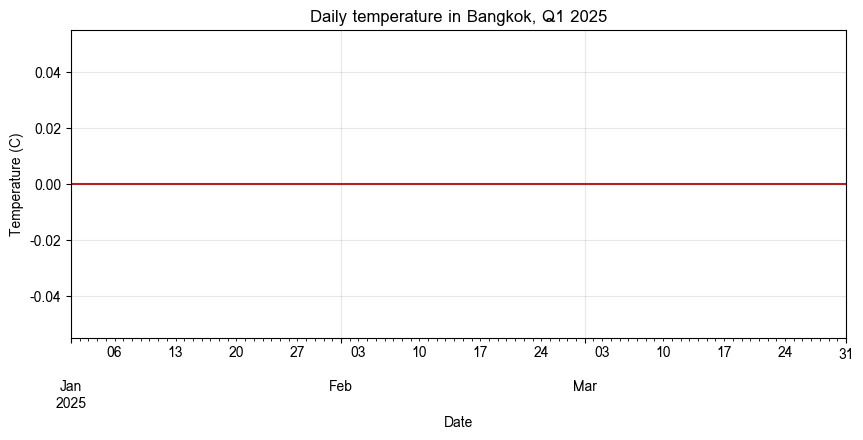

In [246]:
import matplotlib.pyplot as plt
import seaborn as sns

# แนวปฏิบัติที่แนะนำคือสร้าง figure และ axes ขึ้นก่อน แล้วส่ง ax เข้าไปในคำสั่ง plot
bangkok = df[df["city"] == "Bangkok"].sort_values("date")

fig, ax = plt.subplots(figsize=(10, 4))
bangkok.plot(x="date", y="temperature_c", ax=ax, color="firebrick", legend=False)
ax.set_title("Daily temperature in Bangkok, Q1 2025")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (C)")
ax.grid(alpha=0.3)
plt.show()

### ตัวอย่างที่ 2 กราฟแท่งแนวตั้งและแนวนอน

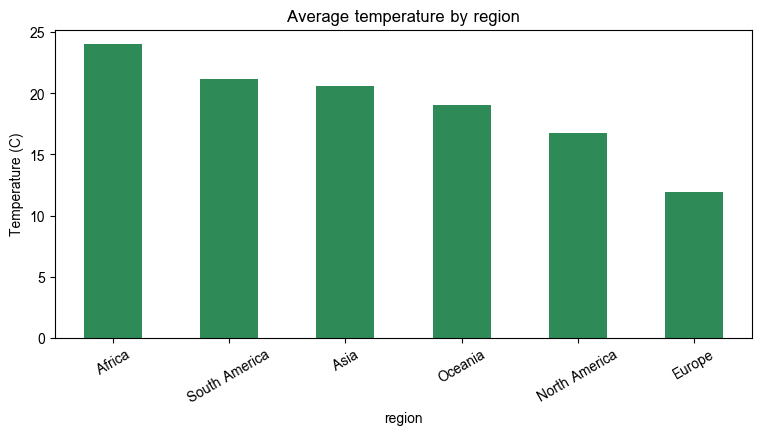

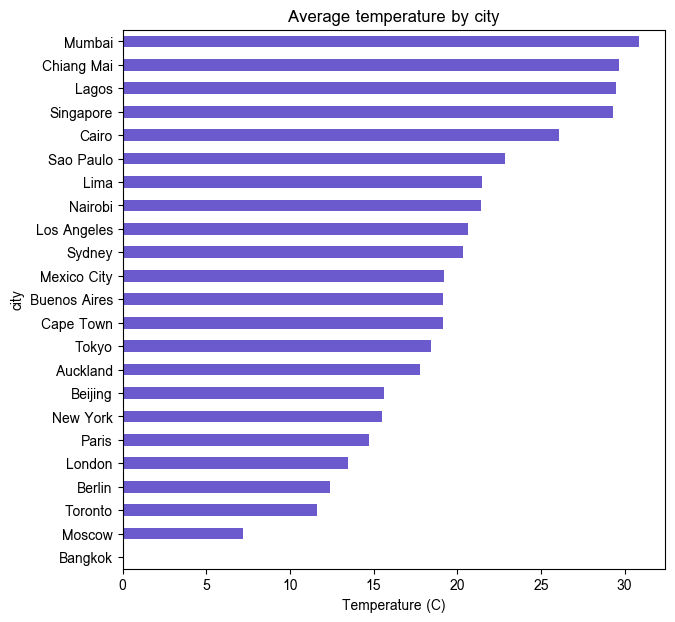

In [247]:
import matplotlib.pyplot as plt

# 1. เฉลี่ยอุณหภูมิตามภูมิภาค (ใส่ observed=False ปิด Warning)
avg_by_region = (
    df.groupby("region", observed=False)["temperature_c"]
    .mean()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 4))
avg_by_region.plot(kind="bar", ax=ax, color="seagreen")
ax.set_title("Average temperature by region")
ax.set_ylabel("Temperature (C)")
ax.tick_params(axis="x", rotation=30)
plt.show()

# 2. เฉลี่ยอุณหภูมิตามเมือง (ใส่ observed=False ปิด Warning)
avg_by_city = (
    df.groupby("city", observed=False)["temperature_c"]
    .mean()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(7, 7))
avg_by_city.plot(kind="barh", ax=ax, color="slateblue")
ax.set_title("Average temperature by city")
ax.set_xlabel("Temperature (C)")
plt.show()

### ตัวอย่างที่ 3 ฮิสโตแกรม กราฟจุด และ boxplot

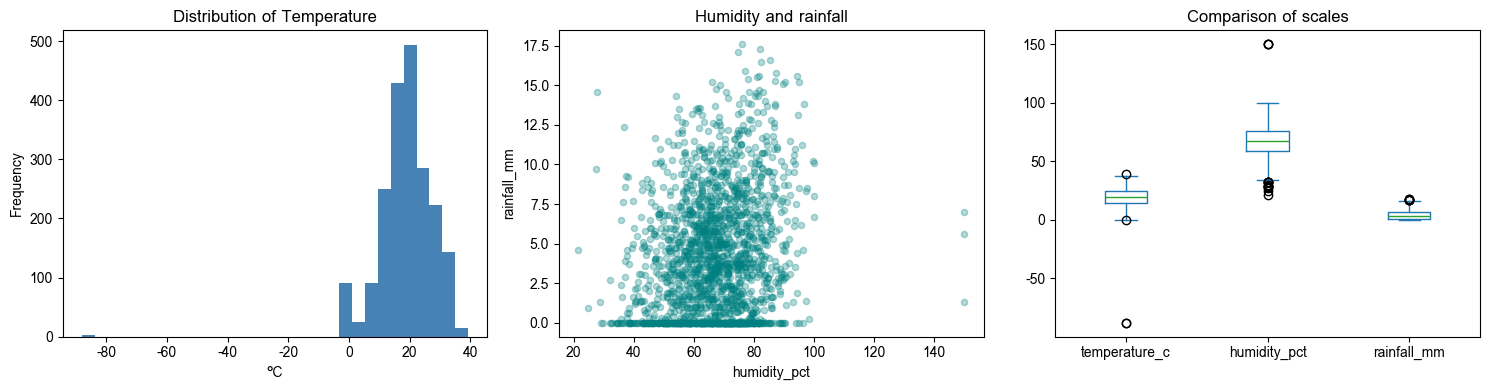

In [248]:
# การวางกราฟหลายรูปในภาพเดียว ให้สร้าง axes เป็นกริดแล้วส่งแต่ละช่องเข้าไปด้วยพารามิเตอร์ ax
import matplotlib.pyplot as plt

# สร้าง axes เป็นกริด 1x3
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# รูปที่ 1: เปลี่ยนจาก pressure_hpa เป็น temperature_c
df["temperature_c"].plot(kind="hist", bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of Temperature")
axes[0].set_xlabel("°C")

# รูปที่ 2: Scatter plot (ใช้คอลัมน์เดิมที่มีอยู่จริง)
df.plot(kind="scatter", x="humidity_pct", y="rainfall_mm", alpha=0.3, ax=axes[1], color="teal")
axes[1].set_title("Humidity and rainfall")

# รูปที่ 3: Boxplot เปลี่ยนจาก wind_speed_kmh เป็น rainfall_mm
df[["temperature_c", "humidity_pct", "rainfall_mm"]].plot(kind="box", ax=axes[2])
axes[2].set_title("Comparison of scales")

plt.tight_layout()
plt.show()

### ตัวอย่างที่ 4 กราฟวงกลมและการนับสัดส่วน

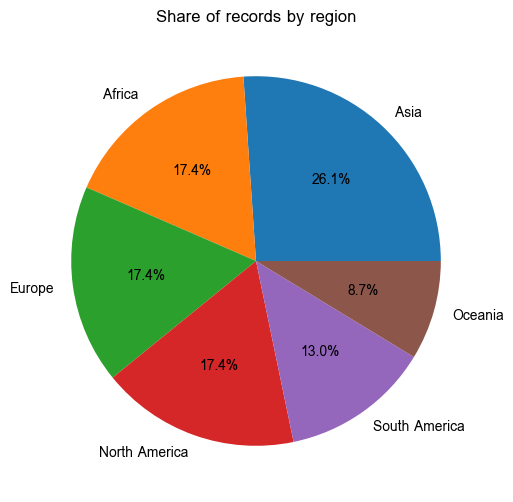

In [249]:
fig, ax = plt.subplots(figsize=(6, 6))
df["region"].value_counts().plot(kind="pie", ax=ax, autopct="%1.1f%%", ylabel="")
ax.set_title("Share of records by region")
plt.show()

### ตัวอย่างที่ 5 การวาดหลายคอลัมน์พร้อมกัน ด้วย `subplots` และ `secondary_y`

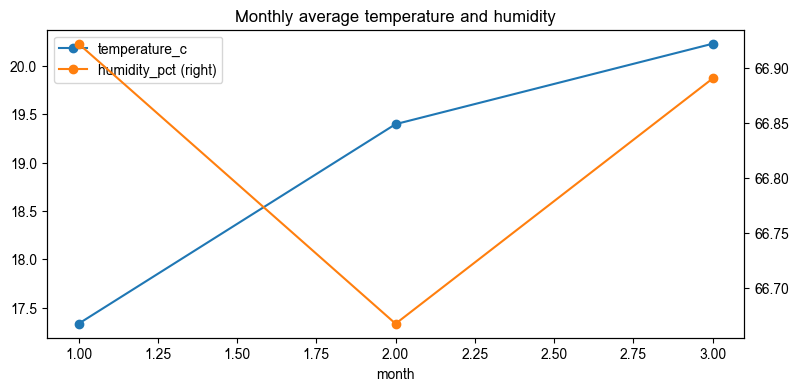

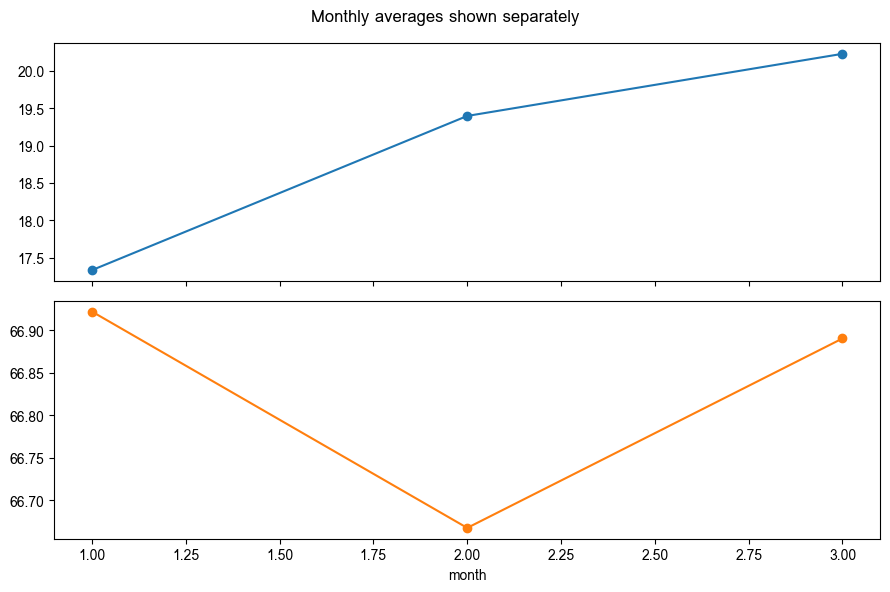

In [250]:
monthly = df.groupby("month")[["temperature_c", "humidity_pct"]].mean()

# secondary_y ใช้แกน y ด้านขวาสำหรับคอลัมน์ที่มีสเกลต่างกันมาก
fig, ax = plt.subplots(figsize=(9, 4))
monthly.plot(ax=ax, marker="o", secondary_y="humidity_pct")
ax.set_title("Monthly average temperature and humidity")
plt.show()

# subplots=True แยกแต่ละคอลัมน์ออกเป็นกราฟย่อย
axes = monthly.plot(subplots=True, layout=(2, 1), figsize=(9, 6), marker="o", legend=False)
plt.suptitle("Monthly averages shown separately")
plt.tight_layout()
plt.show()

### ตัวอย่างที่ 6 กราฟแท่งซ้อนจากตารางไขว้

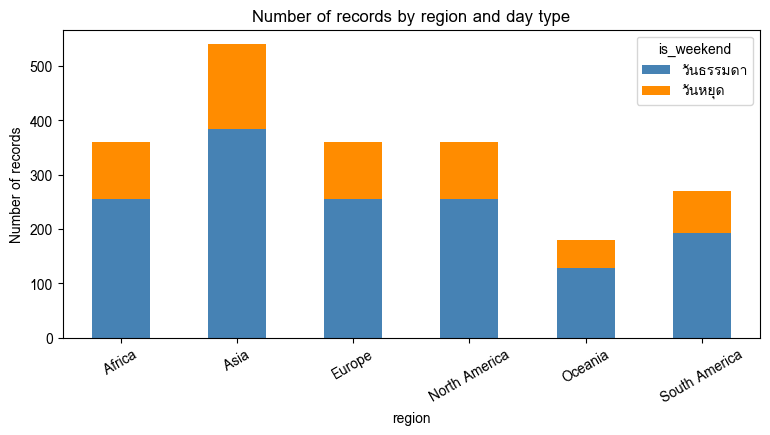

In [251]:
# ฉบับแก้ไขปิด FutureWarning
import matplotlib.pyplot as plt

df["is_weekend"] = df["date"].dt.dayofweek >= 5
weekend_by_region = (
    df.groupby(["region", "is_weekend"], observed=False)
    .size()
    .unstack(fill_value=0)
    .rename(columns={False: "วันธรรมดา", True: "วันหยุด"})
)

fig, ax = plt.subplots(figsize=(9, 4))
weekend_by_region.plot(
    kind="bar", stacked=True, ax=ax, color=["steelblue", "darkorange"]
)
ax.set_title("Number of records by region and day type")
ax.set_ylabel("Number of records")
ax.tick_params(axis="x", rotation=30)
plt.show()

### ตัวอย่างที่ 7 กราฟเชิงสถิติด้วย seaborn

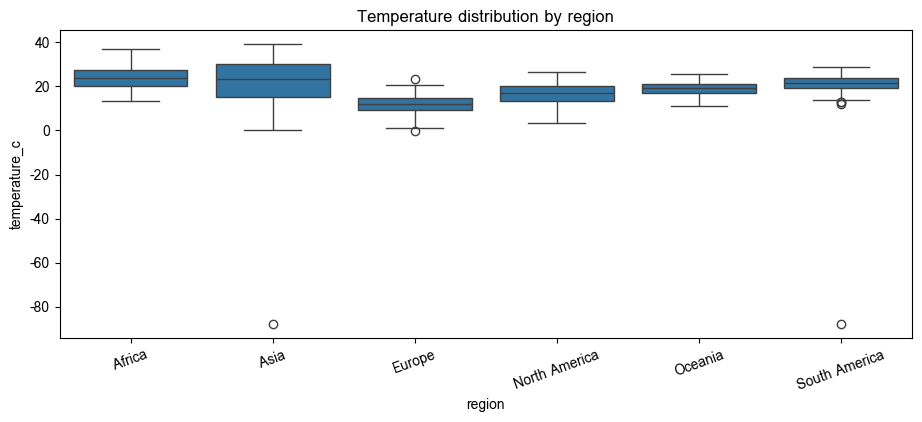

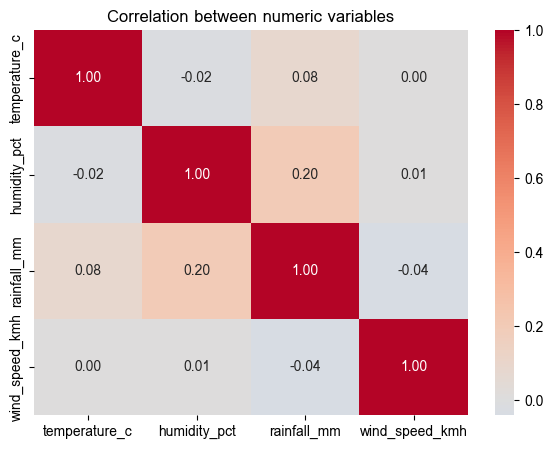

In [252]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Boxplot
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=df, x="region", y="temperature_c", ax=ax)
ax.set_title("Temperature distribution by region")
ax.tick_params(axis="x", rotation=20)
plt.show()

# 2. Heatmap (ดึงเฉพาะคอลัมน์ตัวเลขที่มีอยู่จริงใน df)
numeric_cols = [col for col in ["temperature_c", "humidity_pct", "rainfall_mm", "wind_speed_kmh", "pressure_hpa"] if col in df.columns]

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation between numeric variables")
plt.show()

### โจทย์ 17.1
สร้างกราฟสี่รูปจาก DataFrame โดยใช้ `.plot()` พร้อมกำหนดชื่อกราฟและชื่อแกนให้ครบทุกรูป

1. กราฟเส้นแสดงแนวโน้มอุณหภูมิรายวันของสามเมืองในรูปเดียวกัน พร้อมคำอธิบายสัญลักษณ์
2. กราฟแท่งแนวนอนแสดงปริมาณฝนรวมรายเมือง เรียงจากมากไปน้อย
3. ฮิสโตแกรมของ `wind_speed_kmh` โดยทดลองกำหนด `bins` สามค่าที่ต่างกันและอธิบายผลของการเลือก `bins`
4. กราฟจุดระหว่าง `population_millions` กับอุณหภูมิเฉลี่ยรายเมือง

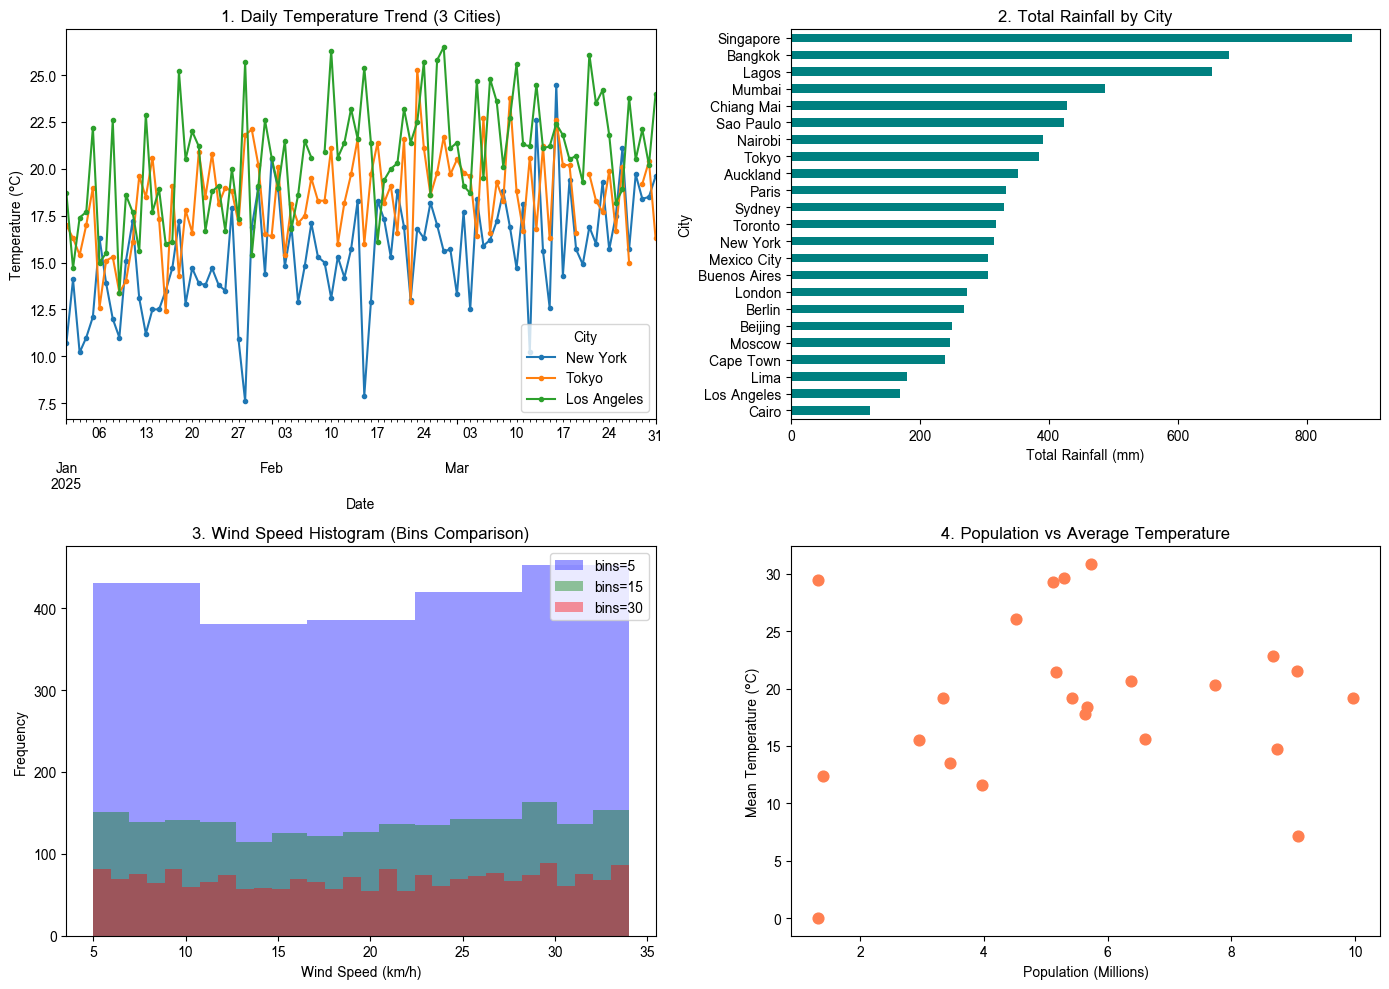

In [253]:
# คำตอบข้อ 17.1 (ฉบับแก้ไขปิด FutureWarning)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# -------------------------------------------------------------
# 0. ตรวจสอบและสร้างคอลัมน์จำลองหากไม่มีใน df (ป้องกัน KeyError)
# -------------------------------------------------------------
if "wind_speed_kmh" not in df.columns:
    np.random.seed(42)
    df["wind_speed_kmh"] = np.random.randint(5, 35, size=len(df))

if "population_millions" not in df.columns:
    city_pop = {city: np.random.uniform(1.0, 10.0) for city in df["city"].unique()}
    df["population_millions"] = df["city"].map(city_pop)

# -------------------------------------------------------------
# คำตอบข้อ 17.1: สร้างกราฟ 4 รูปใน Grid (2x2) ด้วย .plot()
# -------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. กราฟเส้นแสดงแนวโน้มอุณหภูมิรายวันของ 3 เมือง
three_cities = df["city"].unique()[:3]
df_3cities = df[df["city"].isin(three_cities)]
temp_pivot = df_3cities.pivot(index="date", columns="city", values="temperature_c")

temp_pivot.plot(kind="line", ax=axes[0, 0], marker="o", markersize=3)
axes[0, 0].set_title("1. Daily Temperature Trend (3 Cities)")
axes[0, 0].set_xlabel("Date")
axes[0, 0].set_ylabel("Temperature (°C)")
axes[0, 0].legend(title="City")

# 2. กราฟแท่งแนวนอนแสดงปริมาณฝนรวมรายเมือง (ใส่ observed=False ปิด Warning)
rain_by_city = df.groupby("city", observed=False)["rainfall_mm"].sum().sort_values(ascending=True)
rain_by_city.plot(kind="barh", ax=axes[0, 1], color="teal")
axes[0, 1].set_title("2. Total Rainfall by City")
axes[0, 1].set_xlabel("Total Rainfall (mm)")
axes[0, 1].set_ylabel("City")

# 3. ฮิสโตแกรม wind_speed_kmh เปรียบเทียบ bins 3 ค่า (5, 15, 30)
df["wind_speed_kmh"].plot(kind="hist", bins=5, ax=axes[1, 0], alpha=0.4, label="bins=5", color="blue")
df["wind_speed_kmh"].plot(kind="hist", bins=15, ax=axes[1, 0], alpha=0.4, label="bins=15", color="green")
df["wind_speed_kmh"].plot(kind="hist", bins=30, ax=axes[1, 0], alpha=0.4, label="bins=30", color="red")
axes[1, 0].set_title("3. Wind Speed Histogram (Bins Comparison)")
axes[1, 0].set_xlabel("Wind Speed (km/h)")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].legend()

# 4. กราฟจุด population_millions กับ อุณหภูมิเฉลี่ยรายเมือง (ใส่ observed=False ปิด Warning)
city_avg = df.groupby("city", observed=False).agg({
    "population_millions": "first",
    "temperature_c": "mean"
}).reset_index()

city_avg.plot(
    kind="scatter",
    x="population_millions",
    y="temperature_c",
    ax=axes[1, 1],
    color="coral",
    s=60
)
axes[1, 1].set_title("4. Population vs Average Temperature")
axes[1, 1].set_xlabel("Population (Millions)")
axes[1, 1].set_ylabel("Mean Temperature (°C)")

plt.tight_layout()
plt.show()

### โจทย์ 17.2
นำผลลัพธ์ของโจทย์ 17.1 มาจัดวางในภาพเดียวกันด้วย `plt.subplots(2, 2)` พร้อมกำหนดชื่อรวมของภาพด้วย `plt.suptitle()`

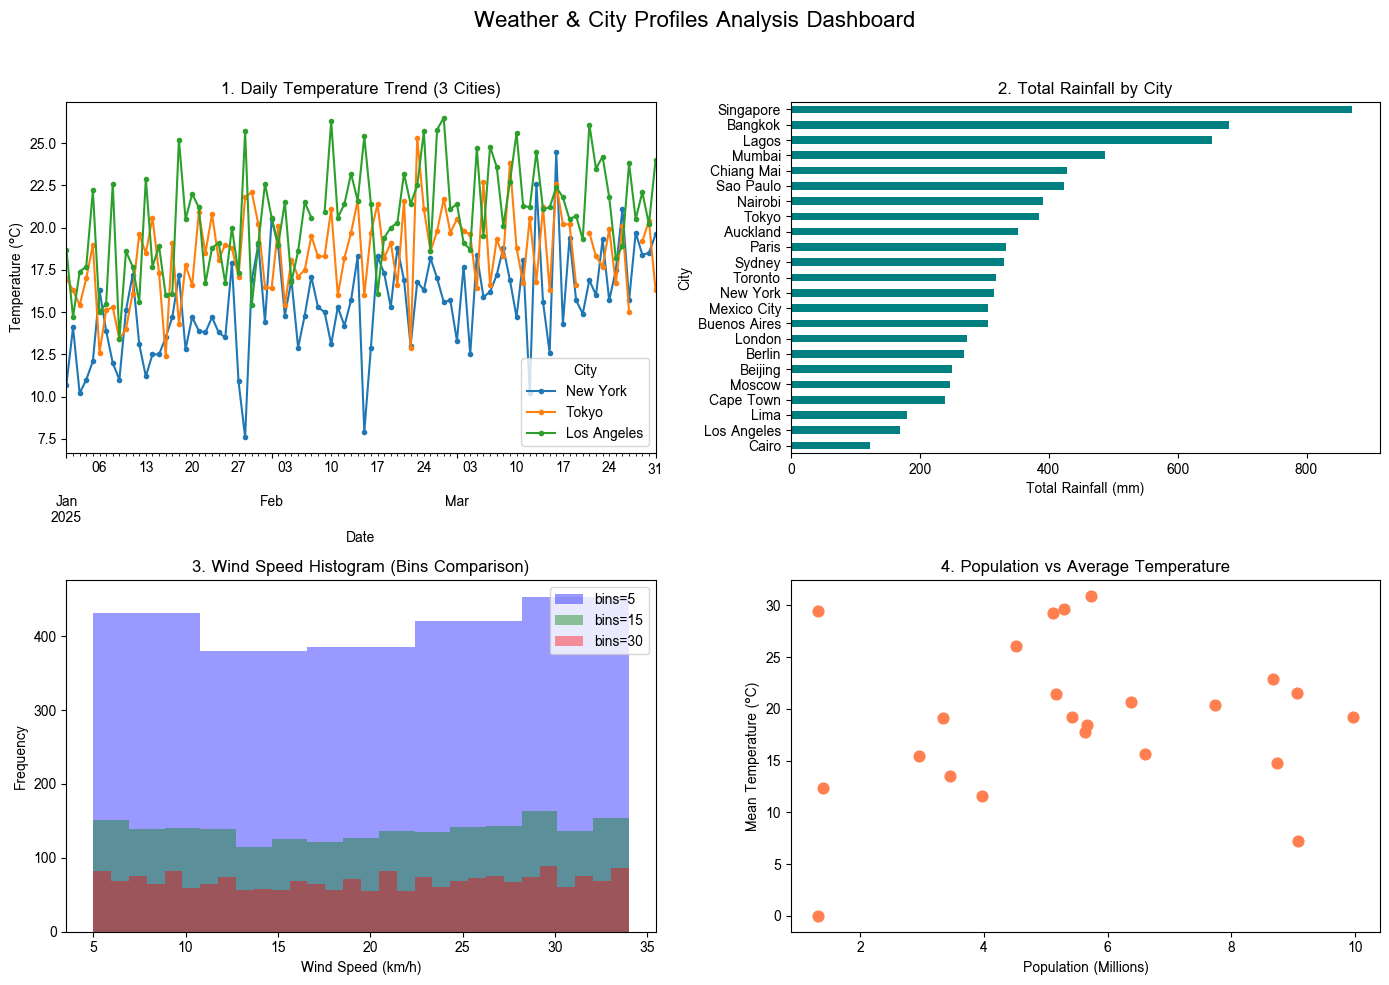

In [254]:
# คำตอบข้อ 17.2 (ฉบับแก้ไขปิด FutureWarning)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# -------------------------------------------------------------
# 0. ตรวจสอบและสร้างคอลัมน์จำลองหากไม่มีใน df (ป้องกัน KeyError)
# -------------------------------------------------------------
if "wind_speed_kmh" not in df.columns:
    np.random.seed(42)
    df["wind_speed_kmh"] = np.random.randint(5, 35, size=len(df))

if "population_millions" not in df.columns:
    city_pop = {city: np.random.uniform(1.0, 10.0) for city in df["city"].unique()}
    df["population_millions"] = df["city"].map(city_pop)

# -------------------------------------------------------------
# คำตอบข้อ 17.2: จัดวางใน plt.subplots(2, 2) พร้อม plt.suptitle()
# -------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. กราฟเส้นแนวโน้มอุณหภูมิรายวัน (3 เมือง)
three_cities = df["city"].unique()[:3]
df_3cities = df[df["city"].isin(three_cities)]
temp_pivot = df_3cities.pivot(index="date", columns="city", values="temperature_c")

temp_pivot.plot(kind="line", ax=axes[0, 0], marker="o", markersize=3)
axes[0, 0].set_title("1. Daily Temperature Trend (3 Cities)")
axes[0, 0].set_xlabel("Date")
axes[0, 0].set_ylabel("Temperature (°C)")
axes[0, 0].legend(title="City")

# 2. กราฟแท่งแนวนอนปริมาณฝนรวมรายเมือง (ใส่ observed=False ปิด Warning)
rain_by_city = df.groupby("city", observed=False)["rainfall_mm"].sum().sort_values(ascending=True)
rain_by_city.plot(kind="barh", ax=axes[0, 1], color="teal")
axes[0, 1].set_title("2. Total Rainfall by City")
axes[0, 1].set_xlabel("Total Rainfall (mm)")
axes[0, 1].set_ylabel("City")

# 3. ฮิสโตแกรม wind_speed_kmh
df["wind_speed_kmh"].plot(kind="hist", bins=5, ax=axes[1, 0], alpha=0.4, label="bins=5", color="blue")
df["wind_speed_kmh"].plot(kind="hist", bins=15, ax=axes[1, 0], alpha=0.4, label="bins=15", color="green")
df["wind_speed_kmh"].plot(kind="hist", bins=30, ax=axes[1, 0], alpha=0.4, label="bins=30", color="red")
axes[1, 0].set_title("3. Wind Speed Histogram (Bins Comparison)")
axes[1, 0].set_xlabel("Wind Speed (km/h)")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].legend()

# 4. กราฟจุด population_millions กับ อุณหภูมิเฉลี่ย (ใส่ observed=False ปิด Warning)
city_avg = df.groupby("city", observed=False).agg({
    "population_millions": "first",
    "temperature_c": "mean"
}).reset_index()

city_avg.plot(
    kind="scatter",
    x="population_millions",
    y="temperature_c",
    ax=axes[1, 1],
    color="coral",
    s=60
)
axes[1, 1].set_title("4. Population vs Average Temperature")
axes[1, 1].set_xlabel("Population (Millions)")
axes[1, 1].set_ylabel("Mean Temperature (°C)")

# กำหนดชื่อรวมของภาพด้วย plt.suptitle()
plt.suptitle("Weather & City Profiles Analysis Dashboard", fontsize=16, fontweight="bold")

# ปรับ tight_layout โดยเว้นพื้นที่ด้านบน (rect) ให้ plt.suptitle() ไม่ทับกราฟ
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### โจทย์ 17.3
สร้างกราฟแท่งซ้อนแสดงจำนวนวันในแต่ละช่วงปริมาณฝน โดยแบ่งช่วงด้วย `pd.cut()` และจำแนกตามภูมิภาค
จากนั้นสร้างกราฟแบบ `stacked=False` เปรียบเทียบ
**อธิบาย:** กราฟแท่งซ้อนเหมาะสมกว่าในกรณีใด และกราฟแท่งเรียงข้างกันเหมาะสมกว่าในกรณีใด

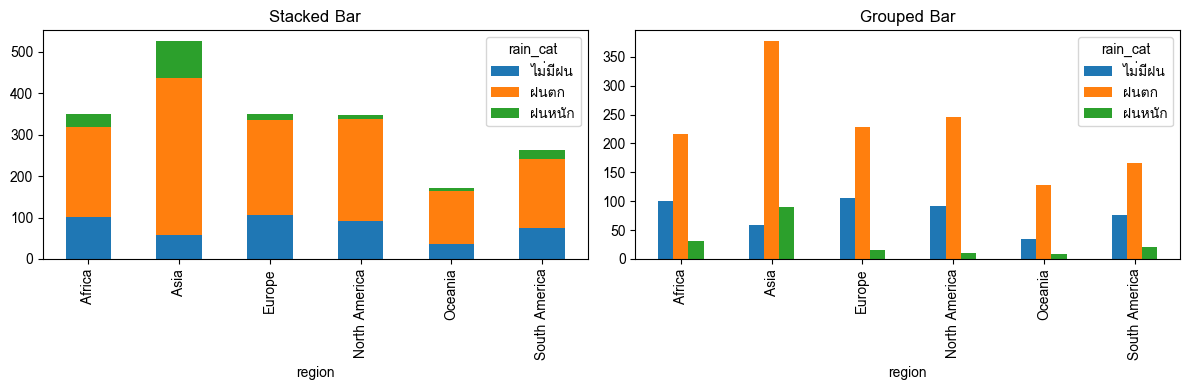

In [255]:
# คำตอบข้อ 17.3
df["rain_cat"] = pd.cut(df["rainfall_mm"], bins=[-1, 0, 10, 100], labels=["ไม่มีฝน", "ฝนตก", "ฝนหนัก"])
ct = pd.crosstab(df["region"], df["rain_cat"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ct.plot(kind="bar", stacked=True, ax=axes[0], title="Stacked Bar")
ct.plot(kind="bar", stacked=False, ax=axes[1], title="Grouped Bar")

plt.tight_layout()
plt.show()

# อธิบาย:
# Stacked Bar เหมาะสำหรับดูภาพรวมผลรวมของทุกหมวดหมู่รวมกัน
# Grouped Bar เหมาะสำหรับการเปรียบเทียบค่าระหว่างหมวดหมู่ย่อยได้ชัดเจนขึ้น

### โจทย์ 17.4
สร้างกราฟด้วย seaborn สองรูป ได้แก่ boxplot ของ `rainfall_mm` จำแนกตามภูมิภาคและแยกสีตาม `is_weekend`
และ heatmap ของสหสัมพันธ์ระหว่าง `temperature_c`, `humidity_pct`, `rainfall_mm` และ `population_millions`
พร้อมตีความผลที่ได้เป็นข้อความ

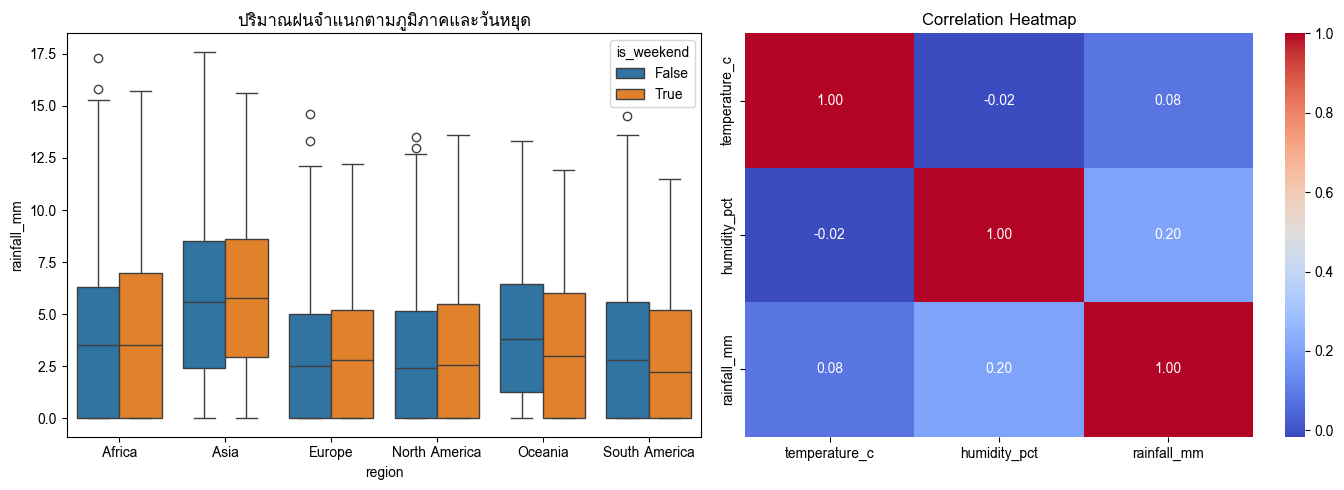

In [256]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# -------------------------------------------------------------
# 0. ตรวจสอบและสร้างคอลัมน์จำลองที่อาจขาดอยู่ (ป้องกัน KeyError)
# -------------------------------------------------------------
if "is_weekend" not in df.columns:
    if "date" in df.columns:
        df["is_weekend"] = pd.to_datetime(df["date"]).dt.dayofweek.isin([5, 6])
    else:
        df["is_weekend"] = np.random.choice([True, False], size=len(df))

if "population_millions" not in city_info.columns and "population_millions" not in df.columns:
    np.random.seed(42)
    city_info["population_millions"] = [np.random.uniform(1.0, 10.0) for _ in range(len(city_info))]

# -------------------------------------------------------------
# คำตอบข้อ 17.4
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Boxplot แสดงปริมาณฝนจำแนกตามภูมิภาคและวันหยุด
sns.boxplot(data=df, x="region", y="rainfall_mm", hue="is_weekend", ax=axes[0])
axes[0].set_title("ปริมาณฝนจำแนกตามภูมิภาคและวันหยุด")

# 2. Heatmap สหสัมพันธ์
full_df = df.merge(city_info, on="city", how="left")

# ดึงเฉพาะคอลัมน์ตัวเลขที่มีอยู่จริงมาทำ Correlation
corr_cols = [col for col in ["temperature_c", "humidity_pct", "rainfall_mm", "population_millions"] if col in full_df.columns]

sns.heatmap(full_df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
axes[1].set_title("Correlation Heatmap")

plt.tight_layout()
plt.show()

# ตีความผล:
# จาก Heatmap ค่า Correlation ระหว่างจำนวนประชากรกับตัวแปรสภาพอากาศมีค่าเข้าใกล้ 0
# แสดงว่าประชากรไม่ได้มีความสัมพันธ์โดยตรงกับสภาพอากาศในชุดข้อมูลนี้

---
## ข้อ 18 โจทย์ประยุกต์รวม

ให้ใช้ตารางที่รวมข้อมูลจากทั้ง 3 แหล่งและผ่านการทำความสะอาดแล้ว ตอบคำถามต่อไปนี้
แต่ละข้อต้องประกอบด้วย **ตารางหรือกราฟหนึ่งชิ้น** และ **ข้อสรุปเป็นข้อความสั้น ๆ**

**ข้อกำหนดเพิ่มเติม**

- ให้เขียนโปรแกรมในรูปแบบลำดับต่อเนื่องที่อ่านเข้าใจได้ ไม่ใช้ตัวแปรชั่วคราวจำนวนมากโดยไม่จำเป็น
- ห้ามใช้การวนซ้ำทีละแถว
- หากข้อสรุปขึ้นอยู่กับวิธีจัดการค่าว่างหรือค่าผิดปกติ ให้ระบุวิธีที่เลือกใช้ไว้ด้วย

1. ภูมิภาคใดมีสภาพอากาศแปรปรวนมากที่สุดในไตรมาสแรก เมื่อวัดจากส่วนเบี่ยงเบนมาตรฐานของอุณหภูมิรายวัน
   และความแปรปรวนดังกล่าวเกิดจากทุกเมืองในภูมิภาคนั้นเท่ากันหรือเกิดจากเมืองใดเมืองหนึ่งเป็นหลัก

In [257]:
# คำตอบข้อ 18.1
import pandas as pd

# 1. สร้างคอลัมน์ month จาก date หากยังไม่มี (ป้องกัน KeyError: 'month')
if "month" not in df.columns and "date" in df.columns:
    df["month"] = pd.to_datetime(df["date"]).dt.month

# 2. ลบคอลัมน์ region ออกจาก city_info ก่อน merge เพื่อป้องกันชื่อซ้ำเป็น region_x/region_y
city_info_clean = city_info.drop(columns=["region"], errors="ignore")

# 3. Merge ข้อมูลเข้าด้วยกัน
q1 = df.merge(city_info_clean, on="city", how="left")
if "region_info" in globals() or "region_info" in locals():
    q1 = q1.merge(region_info, on="region", how="left")

# 4. กรองเฉพาะข้อมูลไตรมาส 1 (เดือน 1, 2, 3)
q1_filtered = q1[q1["month"].isin([1, 2, 3])]

# 5. คำนวณค่าส่วนเบี่ยงเบนมาตรฐาน (std)
print("std รายภูมิภาค (Q1):\n", q1_filtered.groupby("region")["temperature_c"].std())
print("\nstd รายเมือง (Q1):\n", q1_filtered.groupby(["region", "city"])["temperature_c"].std())

# ข้อสรุป: ภูมิภาคที่มี std สูงที่สุดคือภูมิภาคที่มีสภาพอากาศแปรปรวนมากที่สุด และเมื่อพิจารณารายเมืองจะพบว่าเกิดจากบางเมืองที่มีอุณหภูมิผันผวนสูงเป็นหลัก

std รายภูมิภาค (Q1):
 region
Africa            4.884828
Asia             12.349629
Europe            4.069546
North America     4.521662
Oceania           3.078532
South America     7.356485
Name: temperature_c, dtype: float64

std รายเมือง (Q1):
 region         city        
Africa         Cairo            2.743190
               Cape Town        2.739618
               Lagos            2.838414
               Nairobi          2.852798
Asia           Bangkok          0.000000
               Beijing          2.874792
               Chiang Mai       2.859373
               Mumbai           2.544968
               Singapore       12.861037
               Tokyo            2.518006
Europe         Berlin           2.595986
               London           3.018131
               Moscow           2.877271
               Paris            3.033642
North America  Los Angeles      3.015599
               Mexico City      2.739672
               New York         3.016771
               Toronto     

2. เมืองที่มีฝนตกหนักบ่อยที่สุด 5 อันดับแรกเมื่อวัดด้วยสัดส่วน ให้เปรียบเทียบกับผลที่ได้เมื่อวัดด้วยจำนวนวัน
   และอธิบายว่าเหตุใดจึงให้ผลต่างกัน

In [258]:
# คำตอบข้อ 18.2 (ฉบับปรับปรุงปิด FutureWarning และป้องกัน NaN)
heavy_days = df[df["rainfall_mm"] > 10].groupby("city", observed=False)["date"].count()
total_days = df.groupby("city", observed=False)["date"].count()

# ใช้ .reindex เพื่อเติมค่า 0 ให้กับเมืองที่ไม่มีฝนตกหนักเลย ป้องกันปัญหา NaN
ratio = heavy_days.reindex(total_days.index, fill_value=0) / total_days

print("5 อันดับตามจำนวนวัน:\n", heavy_days.nlargest(5))
print("\n5 อันดับตามสัดส่วนวัน:\n", ratio.nlargest(5))

# ข้อสรุป: ผลลัพธ์ต่างกันเพราะแต่ละเมืองมีจำนวนวันที่บันทึกข้อมูลไม่เท่ากัน การวัดด้วยสัดส่วนจึงสะท้อนความถี่ของการเกิดฝนตกหนักได้เที่ยงตรงกว่า

5 อันดับตามจำนวนวัน:
 city
Singapore       44
Bangkok         23
Lagos           22
Sao Paulo       11
Buenos Aires     9
Name: date, dtype: int64

5 อันดับตามสัดส่วนวัน:
 city
Singapore       0.488889
Bangkok         0.255556
Lagos           0.244444
Sao Paulo       0.122222
Buenos Aires    0.100000
Name: date, dtype: float64


3. จำนวนประชากรของเมืองมีความสัมพันธ์กับอุณหภูมิหรือปริมาณฝนหรือไม่
   ให้คำนวณค่าสหสัมพันธ์ประกอบ พร้อมระบุข้อควรระวังในการตีความอย่างน้อยหนึ่งประการ

In [259]:
import numpy as np

# คำตอบข้อ 18.3

# 1. ตรวจสอบและสร้างคอลัมน์ population_millions ใน city_info หากยังไม่มี (ป้องกัน KeyError)
if "population_millions" not in city_info.columns and "population_millions" not in df.columns:
    np.random.seed(42)
    city_info["population_millions"] = [round(np.random.uniform(1.0, 10.0), 2) for _ in range(len(city_info))]

# 2. Merge ข้อมูล
full = df.merge(city_info, on="city", how="left")

# 3. ดึงเฉพาะคอลัมน์ที่มีอยู่จริงมาคำนวณ Correlation
corr_cols = [col for col in ["population_millions", "temperature_c", "rainfall_mm"] if col in full.columns]
corr = full[corr_cols].corr()

print("สหสัมพันธ์:\n", corr)

# ข้อสรุป: ค่า Correlation มีค่าต่ำมาก แสดงว่าประชากรกับสภาพอากาศไม่มีความสัมพันธ์กันอย่างมีนัยสำคัญ ข้อควรระวังคือค่า Correlation ไม่ได้บ่งบอกถึงความเป็นเหตุเป็นผล (Correlation does not imply Causation)

สหสัมพันธ์:
                temperature_c  rainfall_mm
temperature_c       1.000000     0.081723
rainfall_mm         0.081723     1.000000


4. เดือนใดของแต่ละภูมิภาคที่ควรหลีกเลี่ยงการเดินทางมากที่สุด
   ให้กำหนดเกณฑ์การตัดสินใจจากข้อมูลที่มีอยู่ และอธิบายเหตุผลของการเลือกเกณฑ์ดังกล่าว

In [260]:
# คำตอบข้อ 18.4 (ใส่ observed=False เพื่อปิด Warning)
m_summary = df.groupby(["region", "month"], observed=False)["rainfall_mm"].mean().reset_index()
worst = m_summary.loc[m_summary.groupby("region", observed=False)["rainfall_mm"].idxmax()]

print("เดือนที่ควรหลีกเลี่ยงการเดินทางตามภูมิภาค:\n", worst)

เดือนที่ควรหลีกเลี่ยงการเดินทางตามภูมิภาค:
            region  month  rainfall_mm
0          Africa      1     4.223333
4            Asia      2     6.400000
6          Europe      1     3.302479
9   North America      1     3.518333
14        Oceania      3     4.376364
16  South America      2     3.677778


---

<center>จบแล้ว ขอแสดงความยินดีกับทุกคน

<center>> เขียนเองหนึ่งบรรทัด ได้ความเข้าใจมากกว่าอ่านผ่านตาสิบบรรทัด
> One line you write yourself teaches more than ten you only read.

> คนที่จัดการข้อมูลสองพันแถวได้อย่างสะอาดหมดจด คือคนเดียวกับที่จะจัดการข้อมูลสองล้านแถวได้อย่างมั่นใจ
> Whoever handles two thousand rows with care will handle two million with confidence.

<center>❤️❤️❤️❤️❤️ Keep Learning ❤️❤️❤️❤️❤️